# 2. Feature Engineering — Understanding user behaviour
# 2. Merkmalsentwicklung — Nutzerverhalten verstehen

## Purpose
## Ziel

The four datasets have been explored and cleaned. This notebook
turns individual sessions and bookings into meaningful behavioural
features for each user.

Die vier Datensätze wurden untersucht und bereinigt. In diesem
Notebook entwickeln wir aus einzelnen Sessions und Buchungen
aussagekräftige Merkmale für jeden Nutzer.

## Approach
## Vorgehen

1. Load the cleaned datasets and validate their relationships.
2. Connect sessions with user, flight and hotel information.
3. Calculate user-level metrics, such as booking frequency,
   cancellation share and baggage usage.
4. Explore the features using tables and visualisations.
5. Select suitable features and prepare them for clustering.
<!-- -->
1. Die bereinigten Tabellen laden und ihre Beziehungen prüfen.
2. Sessions mit Nutzer-, Flug- und Hotelinformationen verknüpfen.
3. Kennzahlen je Nutzer berechnen, beispielsweise Buchungshäufigkeit,
   Stornierungsanteil und Gepäcknutzung.
4. Die Merkmale mit Tabellen und Visualisierungen untersuchen.
5. Geeignete Merkmale auswählen und für das Clustering vorbereiten.

## Expected result
## Erwartetes Ergebnis

A user-level table with one row per user, supported by an enriched
session table for detailed analysis. Shared trips must not be counted
twice through booking and cancellation sessions. Missing information
and users without bookings are handled explicitly.

The features will support the subsequent segmentation and the
recommendation of suitable customer benefits. Clustering itself
will take place in a separate notebook.

Eine Nutzertabelle mit einer Zeile pro Nutzer sowie eine angereicherte
Sessiontabelle für Detailanalysen. Dieselbe Reise darf durch Buchungs-
und Stornierungssessions nicht doppelt gezählt werden. Fehlende
Informationen und Nutzer ohne Buchungen werden ausdrücklich
berücksichtigt.

Die Merkmale bilden die Grundlage für die anschließende Segmentierung
und die Empfehlung passender Kundenvorteile. Das Clustering selbst
erfolgt in einem separaten Notebook.

In [1]:
# packages for data preparation and visualisation
# pakete für datenaufbereitung und visualisierung
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import HTML, display

# locate the project folder
# projektordner bestimmen
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src").is_dir():
    raise FileNotFoundError(
        "Project folder not found. Check the notebook working directory."
    )

# make shared project modules available
# gemeinsame projektmodule verfügbar machen
project_path = str(project_root.resolve())

if project_path not in sys.path:
    sys.path.insert(0, project_path)

from src.plotting_style import (
    COLORS,
    PALETTE,
    GENDER_COLORS,
    style_overview,
    apply_plot_style,
)

apply_plot_style()

print("Project folder:", project_root)
print("Python environment:", sys.executable)

Project folder: c:\Users\mpero\Desktop\GitHub\TravelTide
Python environment: c:\Users\mpero\Desktop\GitHub\TravelTide\.venv\Scripts\python.exe


## 2.1 Load the cleaned datasets
## 2.1 Bereinigte Datensätze laden

Load the four cleaned CSV files and restore their date columns.
The files remain unchanged.

CSV files preserve the cleaned values, but not pandas data types
or display formatting. After loading, date columns and nullable
integer columns are therefore converted back to their intended
types. This does not repeat or reverse the cleaning.

Die vier bereinigten CSV-Dateien laden und ihre Datumsspalten
wieder in Datumswerte umwandeln. Die Dateien bleiben unverändert.

CSV-Dateien speichern die bereinigten Werte, jedoch keine
pandas-Datentypen oder Anzeigeformatierungen. Nach dem Laden
werden Datums- und Ganzzahlspalten mit möglichen fehlenden Werten
deshalb wieder in die vorgesehenen Datentypen umgewandelt.
Die Bereinigung wird dadurch weder wiederholt noch rückgängig gemacht.

In [2]:
# load cleaned datasets
# bereinigte datensätze laden
processed_path = project_root / "data" / "processed"

users_clean = pd.read_csv(processed_path / "users_clean.csv")
sessions_clean = pd.read_csv(processed_path / "sessions_clean.csv")
flights_clean = pd.read_csv(processed_path / "flights_clean.csv")
hotels_clean = pd.read_csv(processed_path / "hotels_clean.csv")

# restore user dates stored as day.month.year
# nutzerdaten im format tag.monat.jahr wiederherstellen
for column in ["birthdate", "sign_up_date"]:
    users_clean[column] = pd.to_datetime(
        users_clean[column],
        format="%d.%m.%Y",
        errors="raise",
    )

# restore timestamps stored in ISO format
# zeitstempel im ISO-format wiederherstellen
timestamp_columns = [
    (sessions_clean, ["session_start", "session_end"]),
    (flights_clean, ["departure_time", "return_time"]),
    (hotels_clean, ["check_in_time", "check_out_time"]),
]

for table, columns in timestamp_columns:
    for column in columns:
        table[column] = pd.to_datetime(
            table[column],
            format="ISO8601",
            errors="raise",
        )

# restore nullable integer columns
# ganzzahlspalten mit möglichen fehlenden werten wiederherstellen
users_clean["age"] = users_clean["age"].astype("Int64")
flights_clean["travel_days"] = flights_clean["travel_days"].astype("Int64")
hotels_clean["nights"] = hotels_clean["nights"].astype("Int64")

# show the loaded table sizes
# größen der geladenen tabellen anzeigen
cleaned_tables = {
    "Users": users_clean,
    "Sessions": sessions_clean,
    "Flights": flights_clean,
    "Hotels": hotels_clean,
}

loaded_overview = pd.DataFrame([
    {
        "table": name,
        "rows": len(table),
        "columns": table.shape[1],
    }
    for name, table in cleaned_tables.items()
])

display(style_overview(
    loaded_overview,
    "Cleaned datasets — Loaded tables",
    {
        "rows": "{:,.0f}",
        "columns": "{:,.0f}",
    },
))

table,rows,columns
Users,"5,998",15
Sessions,"49,211",15
Flights,"13,717",19
Hotels,"14,313",9


## 2.2 Validate table relationships
## 2.2 Tabellenbeziehungen prüfen

Check unique keys and matching IDs before joining the tables.
Each trip must belong to exactly one user.

Vor dem Verknüpfen eindeutige Schlüssel und passende IDs prüfen.
Jede Reise muss genau einem Nutzer zugeordnet sein.

In [3]:
# establish unique trip-to-user relationships
# eindeutige zuordnung zwischen reisen und nutzern erstellen
trip_users = (
    sessions_clean.loc[
        sessions_clean["trip_id"].notna(),
        ["trip_id", "user_id"],
    ]
    .drop_duplicates()
)

# count relationship problems
# probleme in den tabellenbeziehungen zählen
relationship_checks = pd.DataFrame({
    "check": [
        "Duplicate user IDs",
        "Duplicate session IDs",
        "Duplicate flight trip IDs",
        "Duplicate hotel trip IDs",
        "Session user IDs absent from users",
        "Trip IDs assigned to multiple users",
        "Flight trip IDs absent from sessions",
        "Hotel trip IDs absent from sessions",
    ],
    "problems": [
        int(users_clean["user_id"].duplicated().sum()),
        int(sessions_clean["session_id"].duplicated().sum()),
        int(flights_clean["trip_id"].duplicated().sum()),
        int(hotels_clean["trip_id"].duplicated().sum()),
        int((
            ~sessions_clean["user_id"].isin(users_clean["user_id"])
        ).sum()),
        int(
            trip_users.groupby("trip_id")["user_id"]
            .nunique()
            .gt(1)
            .sum()
        ),
        int((
            ~flights_clean["trip_id"].isin(trip_users["trip_id"])
        ).sum()),
        int((
            ~hotels_clean["trip_id"].isin(trip_users["trip_id"])
        ).sum()),
    ],
})

display(style_overview(
    relationship_checks,
    "Cleaned datasets — Relationship checks",
    {"problems": "{:,.0f}"},
))

if relationship_checks["problems"].gt(0).any():
    raise ValueError(
        "Resolve the relationship problems before joining the tables."
    )

print("Relationship checks passed.")

check,problems
Duplicate user IDs,0
Duplicate session IDs,0
Duplicate flight trip IDs,0
Duplicate hotel trip IDs,0
Session user IDs absent from users,0
Trip IDs assigned to multiple users,0
Flight trip IDs absent from sessions,0
Hotel trip IDs absent from sessions,0


Relationship checks passed.


### Result
### Ergebnis

All relationship checks passed:

- User and session IDs are unique in their respective tables.
- Each trip has at most one flight record and one hotel record.
- Every session belongs to a user in the cleaned users table.
- Each trip belongs to exactly one user, but may appear in
  multiple sessions belonging to that user.
- All flight and hotel trip IDs are present in the sessions table.

No problems were found in these checks. The tables have not yet
been joined or modified.

Alle Prüfungen der Tabellenbeziehungen wurden bestanden:

- Nutzer- und Session-IDs sind in ihrer jeweiligen Tabelle eindeutig.
- Jede Reise hat höchstens einen Flug- und einen Hoteldatensatz.
- Jede Session gehört zu einem Nutzer der bereinigten Nutzertabelle.
- Jede Reise gehört genau einem Nutzer, kann aber in mehreren
  Sessions dieses Nutzers vorkommen.
- Alle Reise-IDs aus Flügen und Hotels sind in der Sessiontabelle
  vorhanden.

Bei diesen Prüfungen wurden keine Probleme gefunden. Die Tabellen
wurden noch nicht zusammengeführt oder verändert.

## 2.3 Enrich the session table
## 2.3 Sessiontabelle anreichern

Add user, flight and hotel information to each session.
Left joins preserve all sessions, including those without bookings.

Trip details may appear in both booking and cancellation sessions.
They must not be summed across sessions as separate bookings.

Jede Session um Nutzer-, Flug- und Hotelinformationen ergänzen.
Left Joins erhalten alle Sessions, auch solche ohne Buchung.

Reisedetails können sowohl in Buchungs- als auch in
Stornierungssessions erscheinen. Sie dürfen nicht über alle
Sessions hinweg als separate Buchungen aufsummiert werden.

In [4]:
# enrich sessions while preserving one row per session
# sessions anreichern und eine zeile pro session erhalten
sessions_enriched = (
    sessions_clean
    .merge(
        users_clean,
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        flights_clean,
        on="trip_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        hotels_clean,
        on="trip_id",
        how="left",
        validate="many_to_one",
    )
)

# verify that every original session is retained exactly once
# prüfen, ob jede ursprüngliche session genau einmal erhalten bleibt
if (
    len(sessions_enriched) != len(sessions_clean)
    or sessions_enriched["session_id"].duplicated().any()
    or set(sessions_enriched["session_id"])
    != set(sessions_clean["session_id"])
):
    raise ValueError("The session structure changed during the joins.")

enrichment_overview = pd.DataFrame({
    "metric": [
        "Sessions before enrichment",
        "Sessions after enrichment",
        "Columns before enrichment",
        "Columns after enrichment",
    ],
    "value": [
        len(sessions_clean),
        len(sessions_enriched),
        sessions_clean.shape[1],
        sessions_enriched.shape[1],
    ],
})

display(style_overview(
    enrichment_overview,
    "Sessions — Enrichment overview",
    {"value": "{:,.0f}"},
))

print("Session enrichment passed.")

metric,value
Sessions before enrichment,"49,211"
Sessions after enrichment,"49,211"
Columns before enrichment,15
Columns after enrichment,55


Session enrichment passed.


### Result
### Ergebnis

The enriched table contains all 49,211 sessions and 55 columns.
Each original session is retained exactly once.

The table provides a shared basis for detailed analysis.
Only selected user-level features will later be used for clustering.

Die angereicherte Tabelle enthält alle 49.211 Sessions und 55 Spalten.
Jede ursprüngliche Session ist genau einmal erhalten geblieben.

Die Tabelle bildet eine gemeinsame Grundlage für Detailanalysen.
Für das spätere Clustering werden gezielt ausgewählte Merkmale
auf Nutzerebene verwendet.

## 2.4 Session count per user
## 2.4 Sessionanzahl je Nutzer

Count the sessions per user and add this first behavioural feature
to the user-level table. All users in the analysis group are retained.

Die Sessions je Nutzer zählen und dieses erste Verhaltensmerkmal
der Nutzertabelle hinzufügen. Alle Nutzer der Analysegruppe bleiben
erhalten.

In [5]:
# count sessions per user
# sessions je nutzer zählen
session_counts = (
    sessions_clean
    .groupby("user_id")
    .size()
    .rename("session_count")
    .reset_index()
)

# create the user-level table with the first behavioural feature
# nutzertabelle mit dem ersten verhaltensmerkmal erstellen
user_features = users_clean.merge(
    session_counts,
    on="user_id",
    how="left",
    validate="one_to_one",
)

# verify user coverage and total session count
# nutzerabdeckung und gesamte sessionanzahl prüfen
if (
    len(user_features) != len(users_clean)
    or user_features["session_count"].isna().any()
    or user_features["session_count"].sum() != len(sessions_clean)
):
    raise ValueError("User or session counts do not match.")

user_features["session_count"] = (
    user_features["session_count"].astype("Int64")
)

session_count_summary = pd.DataFrame({
    "metric": [
        "Users",
        "Total sessions",
        "Minimum sessions per user",
        "Median sessions per user",
        "Average sessions per user",
        "Maximum sessions per user",
    ],
    "value": [
        len(user_features),
        user_features["session_count"].sum(),
        user_features["session_count"].min(),
        user_features["session_count"].median(),
        user_features["session_count"].mean(),
        user_features["session_count"].max(),
    ],
})

display(style_overview(
    session_count_summary,
    "Users — Session count overview",
    {"value": "{:,.2f}"},
))

print("User-level session counts passed.")

metric,value
Users,"5,998.00"
Total sessions,"49,211.00"
Minimum sessions per user,8.00
Median sessions per user,8.00
Average sessions per user,8.20
Maximum sessions per user,12.00


User-level session counts passed.


In [6]:
# preview all columns for the first and last five users
# alle spalten der ersten und letzten fünf nutzer anzeigen
for title, preview in [
    ("User features — First five users", user_features.head()),
    ("User features — Last five users", user_features.tail()),
]:
    display(HTML(
        '<div style="overflow-x:auto;">'
        + style_overview(
            preview,
            title,
            {
                "birthdate": "{:%d.%m.%Y}",
                "sign_up_date": "{:%d.%m.%Y}",
                "age": "{:.0f}",
                "session_count": "{:,.0f}",
            },
        ).to_html()
        + "</div>"
    ))

user_id,birthdate,age,age_group,gender,married,has_children,sign_up_date,home_country,home_city,home_airport,home_airport_city,home_airport_lat,home_airport_lon,home_city_matches_airport_city,session_count
23557,08.12.1958,64,Adult,F,True,False,22.07.2021,USA,New York,LGA,New York,40.777000,-73.872000,True,8
94883,16.03.1972,51,Adult,F,True,False,07.02.2022,USA,Kansas City,MCI,Kansas City,39.297000,-94.714000,True,8
101486,07.12.1972,50,Adult,F,True,True,17.02.2022,USA,Tacoma,TCM,Tacoma,47.138000,-122.476000,True,8
101961,14.09.1980,42,Adult,F,True,False,17.02.2022,USA,Boston,BOS,Boston,42.364000,-71.005000,True,8
106907,17.11.1978,44,Adult,F,True,True,24.02.2022,USA,Miami,TNT,Miami,25.862000,-80.897000,True,8


user_id,birthdate,age,age_group,gender,married,has_children,sign_up_date,home_country,home_city,home_airport,home_airport_city,home_airport_lat,home_airport_lon,home_city_matches_airport_city,session_count
792549,25.01.1978,45,Adult,F,False,False,30.04.2023,USA,Kansas City,MCI,Kansas City,39.297000,-94.714000,True,8
796032,28.12.1972,50,Adult,F,True,False,01.05.2023,Canada,Winnipeg,YAV,St. Andrews,50.056000,-97.032000,False,8
801660,02.11.1969,53,Adult,F,True,True,03.05.2023,Canada,Toronto,YKZ,Markham,43.862000,-79.370000,False,8
811077,22.02.1979,44,Adult,F,True,True,06.05.2023,USA,Knoxville,TYS,Knoxville,35.812000,-83.993000,True,8
844489,09.05.2000,23,Junior,M,False,True,18.05.2023,USA,El Paso,BIF,El Paso,31.849000,-106.380000,True,8


### Distribution of sessions per user
### Verteilung der Sessionanzahl je Nutzer

Show how many users have each session count.
The analysis group only includes users with more than seven
sessions in the selected period.

Zeigen, wie viele Nutzer die jeweilige Sessionanzahl haben.
Die Analysegruppe enthält ausschließlich Nutzer mit mehr als
sieben Sessions im ausgewählten Zeitraum.

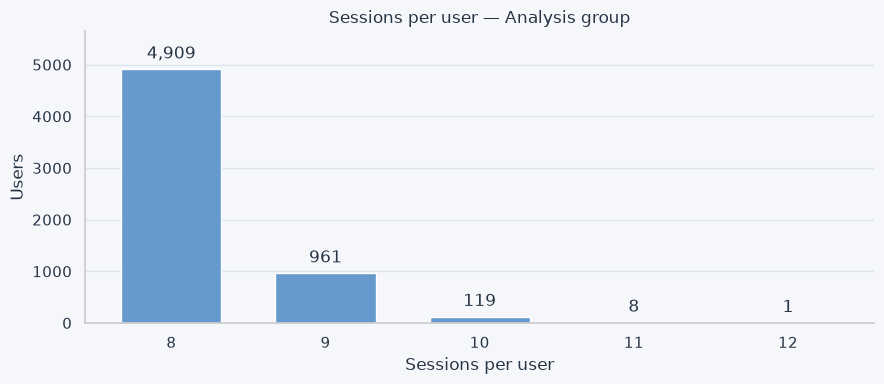

In [7]:
# count users for each session count
# nutzer je sessionanzahl zählen
session_count_distribution = (
    user_features["session_count"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    session_count_distribution.index.astype(int),
    session_count_distribution.to_numpy(dtype=int),
    color=COLORS["blue"],
    width=0.65,
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,}"
        for count in session_count_distribution
    ],
    padding=5,
    color=COLORS["text"],
)

ax.set(
    title="Sessions per user — Analysis group",
    xlabel="Sessions per user",
    ylabel="Users",
)

ax.set_xticks(
    session_count_distribution.index.astype(int)
)
ax.set_ylim(
    0,
    session_count_distribution.max() * 1.15,
)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Result
### Ergebnis

Most users (4,909 of 5,998; 81.8%) have exactly eight sessions.
A further 961 users have nine sessions; only 128 have ten or more.

Session counts vary little within this cohort. This must be
considered when selecting features for clustering. The distribution
describes the selected analysis group, not all TravelTide users.

Die meisten Nutzer (4.909 von 5.998; 81,8 %) haben genau acht
Sessions. Weitere 961 Nutzer haben neun Sessions; nur 128 haben
zehn oder mehr.

Die Sessionanzahl variiert innerhalb dieser Kohorte nur wenig.
Das berücksichtigen wir bei der späteren Merkmalsauswahl für das
Clustering. Die Verteilung beschreibt die ausgewählte Analysegruppe,
nicht alle TravelTide-Nutzer.

## 2.5 Average session duration per user
## 2.5 Durchschnittliche Sessiondauer je Nutzer

Calculate the average session duration for each user, excluding
cancellation sessions because of their distinct duration pattern.
Sessions without a cancellation flag may include browsing or bookings.

Cancellation sessions remain in the datasets and will be analysed
separately.

Die durchschnittliche Sessiondauer je Nutzer berechnen.
Stornierungssessions werden wegen ihres abweichenden Zeitmusters
für diese Kennzahl ausgeschlossen. Sessions ohne Stornierungskennzeichnung
können sowohl reine Suche als auch Buchungen enthalten.

Die Stornierungssessions bleiben in den Datensätzen erhalten
und werden separat ausgewertet.

In [8]:
# select sessions without a cancellation flag
# sessions ohne stornierungskennzeichnung auswählen
non_cancellation_sessions = sessions_clean.loc[
    sessions_clean["cancellation"].eq(False)
].copy()

# calculate average duration per user
# durchschnittliche dauer je nutzer berechnen
user_session_duration = (
    non_cancellation_sessions
    .groupby("user_id")["session_duration_minutes"]
    .mean()
    .rename("avg_session_duration_minutes_non_cancel")
    .reset_index()
)

# add the feature without changing the user count
# merkmal ergänzen, ohne die nutzeranzahl zu verändern
duration_feature = "avg_session_duration_minutes_non_cancel"

user_features = (
    user_features
    .drop(columns=[duration_feature], errors="ignore")
    .merge(
        user_session_duration,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

if len(user_features) != len(users_clean):
    raise ValueError("The user count changed.")

duration_summary = pd.DataFrame({
    "metric": [
        "Users with known average duration",
        "Users with cancellation sessions only",
        "Minimum user average — Minutes",
        "Median user average — Minutes",
        "Maximum user average — Minutes",
    ],
    "value": [
        user_features[duration_feature].notna().sum(),
        user_features[duration_feature].isna().sum(),
        user_features[duration_feature].min(),
        user_features[duration_feature].median(),
        user_features[duration_feature].max(),
    ],
})

display(style_overview(
    duration_summary,
    "Users — Average session duration excluding cancellations",
    {"value": "{:,.2f}"},
))

metric,value
Users with known average duration,"5,998.00"
Users with cancellation sessions only,0.00
Minimum user average — Minutes,0.53
Median user average — Minutes,1.90
Maximum user average — Minutes,11.91


### Result
### Ergebnis

An average session duration could be calculated for all 5,998 users.
No user has cancellation sessions only.

Individual user averages range from 0.53 to 11.91 minutes.
The median of these user averages is 1.90 minutes.
These values describe averages per user, not individual sessions.

Für alle 5.998 Nutzer konnte eine durchschnittliche Sessiondauer
berechnet werden. Kein Nutzer hat ausschließlich Stornierungssessions.

Die individuellen Nutzerdurchschnitte reichen von 0,53 bis
11,91 Minuten. Der Median dieser Durchschnitte beträgt 1,90 Minuten.
Die Werte beschreiben Durchschnitte je Nutzer, keine einzelnen Sessions.

## 2.6 Share of sessions with a booking
## 2.6 Anteil der Sessions mit Buchung

For each user, calculate the percentage of non-cancellation sessions
with a flight booking, a hotel booking, or both.

A session with both booking flags counts once. Cancellation sessions
are excluded from both the numerator and denominator because their
booking flags do not represent new bookings.

Je Nutzer den prozentualen Anteil der Sessions ohne Stornierung
berechnen, in denen ein Flug, ein Hotel oder beides gebucht wurde.

Eine Session mit beiden Buchungskennzeichnungen zählt einmal.
Stornierungssessions werden aus Zähler und Nenner ausgeschlossen,
da ihre Buchungskennzeichnungen keine neuen Buchungen darstellen.

In [9]:
# identify booking sessions, excluding cancellations
# buchungssessions erkennen, stornierungen ausschließen
booking_sessions = (
    sessions_clean.loc[
        sessions_clean["cancellation"].eq(False),
        ["user_id", "flight_booked", "hotel_booked"],
    ]
    .assign(
        has_booking=lambda df: (
            df["flight_booked"].eq(True)
            | df["hotel_booked"].eq(True)
        )
    )
)

# calculate the numerator and denominator per user
# zähler und nenner je nutzer berechnen
user_booking_metrics = (
    booking_sessions
    .groupby("user_id")
    .agg(
        non_cancellation_session_count=("has_booking", "size"),
        booking_session_count=("has_booking", "sum"),
    )
    .reset_index()
)

user_booking_metrics["booking_session_share_pct"] = (
    user_booking_metrics["booking_session_count"]
    / user_booking_metrics["non_cancellation_session_count"]
    * 100
)

# add metrics; allow the cell to be rerun without duplicate columns
# kennzahlen ergänzen; doppelte spalten beim erneuten ausführen vermeiden
booking_columns = [
    "non_cancellation_session_count",
    "booking_session_count",
    "booking_session_share_pct",
]

user_features = (
    user_features
    .drop(columns=booking_columns, errors="ignore")
    .merge(
        user_booking_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# validate coverage and percentage limits for this cohort
# abdeckung und prozentgrenzen für diese kohorte prüfen
if (
    len(user_features) != len(users_clean)
    or user_features[booking_columns].isna().any().any()
    or not user_features["booking_session_share_pct"]
        .between(0, 100).all()
):
    raise ValueError("Check the user-level booking metrics.")

for column in [
    "non_cancellation_session_count",
    "booking_session_count",
]:
    user_features[column] = user_features[column].astype("Int64")

# summarise user-level booking shares
# buchungsanteile auf nutzerebene zusammenfassen
shares = user_features["booking_session_share_pct"]

booking_share_summary = pd.DataFrame({
    "metric": [
        "Sessions excluding cancellations",
        "Sessions with a booking",
        "Users without a booking session",
        "Lowest percentage of sessions with a booking",
        "Median percentage of sessions with a booking",
        "Average percentage of sessions with a booking",
        "Highest percentage of sessions with a booking",
    ],
    "value": [
        f"{len(booking_sessions):,}",
        f"{int(booking_sessions['has_booking'].sum()):,}",
        f"{int(user_features['booking_session_count'].eq(0).sum()):,}",
        f"{shares.min():.1f}%",
        f"{shares.median():.1f}%",
        f"{shares.mean():.1f}%",
        f"{shares.max():.1f}%",
    ],
})

display(style_overview(
    booking_share_summary,
    "Users — Share of sessions with a booking",
))

print("User-level booking shares passed.")

metric,value
Sessions excluding cancellations,"48,601"
Sessions with a booking,"16,092"
Users without a booking session,458
Lowest percentage of sessions with a booking,0.0%
Median percentage of sessions with a booking,37.5%
Average percentage of sessions with a booking,33.3%
Highest percentage of sessions with a booking,100.0%


User-level booking shares passed.


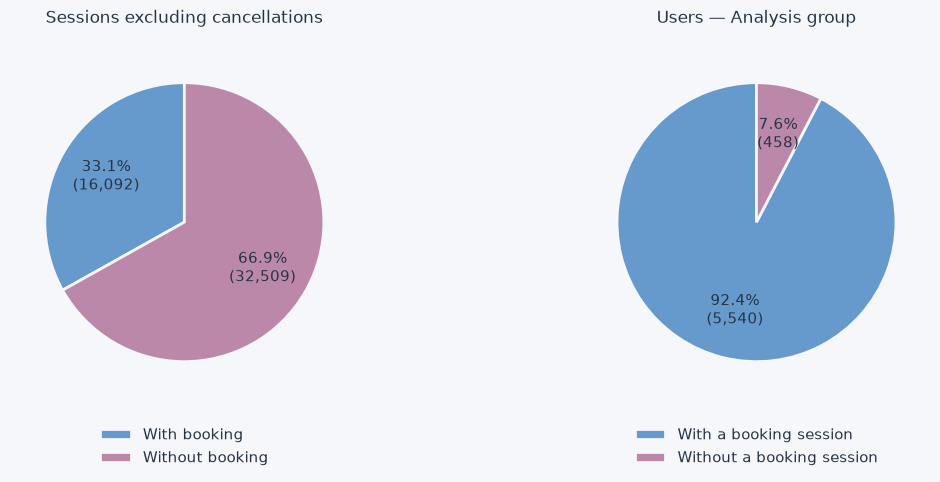

In [10]:
# compare booking activity at session and user level
# buchungsaktivität auf session- und nutzerebene vergleichen
session_counts = [
    int(booking_sessions["has_booking"].sum()),
    int((~booking_sessions["has_booking"]).sum()),
]

user_counts = [
    int(user_features["booking_session_count"].gt(0).sum()),
    int(user_features["booking_session_count"].eq(0).sum()),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

chart_settings = [
    (
        axes[0],
        session_counts,
        ["With booking", "Without booking"],
        "Sessions excluding cancellations",
    ),
    (
        axes[1],
        user_counts,
        ["With a booking session", "Without a booking session"],
        "Users — Analysis group",
    ),
]

for ax, counts, labels, title in chart_settings:
    total = sum(counts)

    wedges, _, _ = ax.pie(
        counts,
        colors=[COLORS["blue"], COLORS["lavender"]],
        startangle=90,
        autopct=lambda pct, total=total: (
            f"{pct:.1f}%\n({round(pct / 100 * total):,})"
        ),
        pctdistance=0.65,
        textprops={
            "color": COLORS["text"],
            "fontsize": 11,
        },
        wedgeprops={
            "edgecolor": COLORS["background"],
            "linewidth": 2,
        },
    )

    ax.set_title(title, pad=18)
    ax.legend(
        wedges,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.05),
        frameon=False,
    )

fig.tight_layout()
plt.show()

### Result
### Ergebnis

Of 48,601 non-cancellation sessions, 16,092 contain a flight
booking, a hotel booking, or both.

A total of 458 users have no booking session in the selected period.
They remain in the user-level table with a booking percentage of 0%.

The median user-level percentage is 37.5%; the average is 33.3%.
Each user has equal weight in this average. The overall percentage
across all non-cancellation sessions is approximately 33.1%.

Von 48.601 Sessions ohne Stornierung enthalten 16.092 eine Flugbuchung,
eine Hotelbuchung oder beides.

458 Nutzer haben im ausgewählten Zeitraum keine Buchungssession.
Sie bleiben mit einem Buchungsanteil von 0 % in der Nutzertabelle.

Der Median der je Nutzer berechneten Anteile beträgt 37,5 %,
der Durchschnitt 33,3 %. Dabei wird jeder Nutzer gleich gewichtet.
Der Gesamtanteil über alle Sessions ohne Stornierung beträgt
rund 33,1 %.

## 2.7 Create a unique trip-level table
## 2.7 Eindeutige Reisetabelle erstellen

Create one row per trip and link it to its user.
Record whether a booking session and a cancellation session
are present in the selected session export.

Cancellation sessions do not count as new bookings.
A missing booking session does not prove that no booking occurred:
the EDA identified seven bookings outside the exported period.

Eine Zeile je Reise erstellen und dem zugehörigen Nutzer zuordnen.
Festhalten, ob eine Buchungssession und eine Stornierungssession
im ausgewählten Sessionexport vorhanden sind.

Stornierungssessions zählen nicht als neue Buchungen.
Eine fehlende Buchungssession bedeutet nicht, dass keine Buchung
stattgefunden hat: Die EDA identifizierte sieben Buchungen
außerhalb des exportierten Zeitraums.

In [11]:
# select sessions with a trip ID
# sessions mit reise-ID auswählen
trip_sessions = sessions_clean.loc[
    sessions_clean["trip_id"].notna()
].copy()

# distinguish actual booking sessions from cancellation sessions
# buchungssessions von stornierungssessions unterscheiden
trip_sessions["is_booking_session"] = (
    trip_sessions["cancellation"].eq(False)
    & (
        trip_sessions["flight_booked"].eq(True)
        | trip_sessions["hotel_booked"].eq(True)
    )
)

# summarise session evidence once per trip
# sessioninformationen einmal je reise zusammenfassen
trip_status = (
    trip_sessions
    .groupby("trip_id")
    .agg(
        booking_session_recorded=("is_booking_session", "any"),
        cancellation_recorded=("cancellation", "any"),
    )
    .reset_index()
)

# connect each trip to its user
# jede reise ihrem nutzer zuordnen
trips = trip_users.merge(
    trip_status,
    on="trip_id",
    how="left",
    validate="one_to_one",
)

if (
    trips["trip_id"].duplicated().any()
    or len(trips) != sessions_clean["trip_id"].nunique()
    or trips[
        ["booking_session_recorded", "cancellation_recorded"]
    ].isna().any().any()
):
    raise ValueError("Check the trip-level table.")

trip_overview = pd.DataFrame({
    "metric": [
        "Distinct trips",
        "Trips with a booking session in the filtered data",
        "Trips with a cancellation session in the filtered data",
        "Trips without a booking session in the filtered data",
    ],
    "trips": [
        len(trips),
        int(trips["booking_session_recorded"].sum()),
        int(trips["cancellation_recorded"].sum()),
        int((~trips["booking_session_recorded"]).sum()),
    ],
})

display(style_overview(
    trip_overview,
    "Trips — Unique trips and recorded sessions",
    {"trips": "{:,.0f}"},
))

print("Trip-level table passed.")

metric,trips
Distinct trips,"16,099"
Trips with a booking session in the filtered data,"16,092"
Trips with a cancellation session in the filtered data,610
Trips without a booking session in the filtered data,7


Trip-level table passed.


### Result
### Ergebnis

The filtered data contains 16,099 distinct trips.
A booking session is present for 16,092 trips, and a cancellation
session is present for 610 trips.

These categories overlap: 603 trips have both a booking session
and a cancellation session in the filtered data. The remaining
seven cancellation trips were booked before the selected period,
as confirmed during the EDA using the full database.

Die gefilterten Daten enthalten 16.099 eindeutige Reisen.
Für 16.092 Reisen ist eine Buchungssession vorhanden, für 610 Reisen
eine Stornierungssession.

Die Kategorien überschneiden sich: 603 Reisen haben sowohl eine
Buchungs- als auch eine Stornierungssession in den gefilterten Daten.
Die übrigen sieben stornierten Reisen wurden vor dem ausgewählten
Zeitraum gebucht. Dies wurde während der EDA anhand der vollständigen
Datenbank bestätigt.

## 2.8 Share of trips with a recorded cancellation
## 2.8 Anteil der Reisen mit verzeichneter Stornierung

For each user, divide the number of trips with a recorded cancellation
by the number of distinct trips present in the filtered data.

The seven trips booked before the selected period are included.
Users without trips receive a missing percentage rather than 0%.

This metric describes recorded activity within the available period.
It does not measure the final cancellation rate of all bookings
made during that period.

Je Nutzer die Anzahl der Reisen mit verzeichneter Stornierung
durch die Anzahl eindeutiger Reisen in den gefilterten Daten teilen.

Die sieben vor dem ausgewählten Zeitraum gebuchten Reisen werden
einbezogen. Nutzer ohne Reisen erhalten einen fehlenden Prozentwert
statt 0 %.

Die Kennzahl beschreibt die verzeichneten Aktivitäten im verfügbaren
Zeitraum. Sie ist keine abschließende Stornierungsquote aller
in diesem Zeitraum getätigten Buchungen.

In [12]:
# count distinct trips and recorded cancellations per user
# eindeutige reisen und verzeichnete stornierungen je nutzer zählen
user_trip_metrics = (
    trips
    .groupby("user_id")
    .agg(
        trip_count=("trip_id", "size"),
        cancelled_trip_count=("cancellation_recorded", "sum"),
    )
    .reset_index()
)

trip_columns = [
    "trip_count",
    "cancelled_trip_count",
    "cancelled_trip_share_pct",
]

user_features = (
    user_features
    .drop(columns=trip_columns, errors="ignore")
    .merge(
        user_trip_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# users without trips have zero counts, but an unknown percentage
# nutzer ohne reisen haben anzahl null, aber einen unbekannten anteil
for column in ["trip_count", "cancelled_trip_count"]:
    user_features[column] = (
        user_features[column].fillna(0).astype("Int64")
    )

user_features["cancelled_trip_share_pct"] = (
    user_features["cancelled_trip_count"]
    / user_features["trip_count"].where(
        user_features["trip_count"].gt(0)
    )
    * 100
)

# verify totals and valid percentage limits
# gesamtzahlen und gültige prozentgrenzen prüfen
known_shares = user_features["cancelled_trip_share_pct"].dropna()

if (
    len(user_features) != len(users_clean)
    or user_features["trip_count"].sum() != len(trips)
    or user_features["cancelled_trip_count"].sum()
        != trips["cancellation_recorded"].sum()
    or not known_shares.between(0, 100).all()
):
    raise ValueError("Check the trip and cancellation metrics.")

cancellation_overview = pd.DataFrame({
    "metric": [
        "Distinct trips",
        "Trips with a recorded cancellation",
        "Users with trips",
        "Users without trips — Percentage unknown",
        "Users with a recorded cancellation",
        "Overall share of trips with a recorded cancellation",
    ],
    "value": [
        f"{len(trips):,}",
        f"{int(trips['cancellation_recorded'].sum()):,}",
        f"{int(user_features['trip_count'].gt(0).sum()):,}",
        f"{int(user_features['trip_count'].eq(0).sum()):,}",
        f"{int(user_features['cancelled_trip_count'].gt(0).sum()):,}",
        f"{trips['cancellation_recorded'].mean() * 100:.1f}%",
    ],
})

display(style_overview(
    cancellation_overview,
    "Trips and users — Recorded cancellations",
))

print("User-level cancellation metrics passed.")


metric,value
Distinct trips,"16,099"
Trips with a recorded cancellation,610
Users with trips,"5,542"
Users without trips — Percentage unknown,456
Users with a recorded cancellation,595
Overall share of trips with a recorded cancellation,3.8%


User-level cancellation metrics passed.


### Cancellation behaviour across users
### Stornierungsverhalten der Nutzer

Compare users with and without recorded cancellations.
Then examine cancellation percentages among users with at least
one recorded cancellation.

Users without trips are excluded from these charts because their
cancellation percentage is unknown.

Nutzer mit und ohne verzeichnete Stornierungen vergleichen.
Anschließend die Stornierungsanteile der Nutzer mit mindestens
einer verzeichneten Stornierung untersuchen.

Nutzer ohne Reisen werden in diesen Grafiken nicht berücksichtigt,
da ihr Stornierungsanteil unbekannt ist.

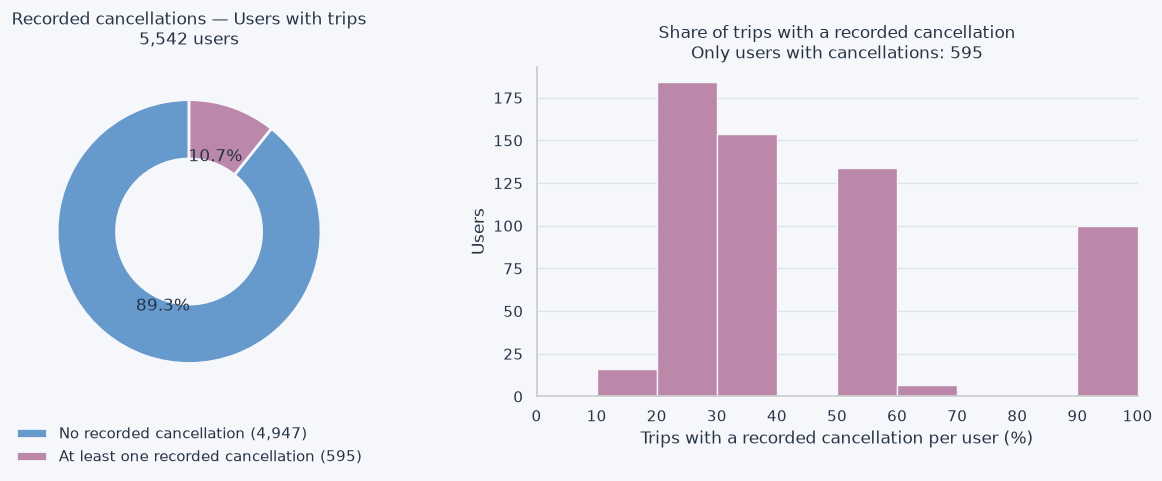

In [13]:
# select users with trips and users with recorded cancellations
# nutzer mit reisen und nutzer mit verzeichneten stornierungen auswählen
users_with_trips = user_features.loc[
    user_features["trip_count"].gt(0)
]

users_with_cancellations = users_with_trips.loc[
    users_with_trips["cancelled_trip_count"].gt(0)
]

cancellation_user_counts = [
    int(users_with_trips["cancelled_trip_count"].eq(0).sum()),
    len(users_with_cancellations),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# show how many users have a recorded cancellation
# zeigen, wie viele nutzer eine verzeichnete stornierung haben
wedges, _, _ = axes[0].pie(
    cancellation_user_counts,
    colors=[COLORS["blue"], COLORS["lavender"]],
    startangle=90,
    autopct="%1.1f%%",
    textprops={"color": COLORS["text"]},
    wedgeprops={
        "width": 0.45,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
)

axes[0].set_title(
    f"Recorded cancellations — Users with trips\n"
    f"{len(users_with_trips):,} users",
    pad=16,
)

axes[0].legend(
    wedges,
    [
        f"No recorded cancellation ({cancellation_user_counts[0]:,})",
        f"At least one recorded cancellation ({cancellation_user_counts[1]:,})",
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    frameon=False,
)

# examine percentages among users who have cancelled
# anteile bei nutzern mit stornierung untersuchen
axes[1].hist(
    users_with_cancellations[
        "cancelled_trip_share_pct"
    ].to_numpy(dtype=float),
    bins=np.linspace(0, 100, 11),
    color=COLORS["lavender"],
    edgecolor=COLORS["background"],
)

axes[1].set(
    title=(
        "Share of trips with a recorded cancellation\n"
        f"Only users with cancellations: "
        f"{len(users_with_cancellations):,}"
    ),
    xlabel="Trips with a recorded cancellation per user (%)",
    ylabel="Users",
    xlim=(0, 100),
)

axes[1].set_xticks(range(0, 101, 10))
axes[1].grid(axis="x", visible=False)
axes[1].set_axisbelow(True)

fig.tight_layout()
plt.show()

### Result
### Ergebnis

Of the 5,542 users with trips, 595 (10.7%) have at least one
recorded cancellation. The remaining 4,947 (89.3%) have none
recorded in the filtered data.

The histogram shows cancellation percentages for these 595 users.
Each bar counts users, not cancelled trips.

A high percentage can result from very few trips. Cancellation
percentages must therefore be interpreted together with trip counts.

Von den 5.542 Nutzern mit Reisen haben 595 (10,7 %) mindestens
eine verzeichnete Stornierung. Für die übrigen 4.947 (89,3 %) ist
in den gefilterten Daten keine Stornierung verzeichnet.

Das Histogramm zeigt die Stornierungsanteile dieser 595 Nutzer.
Jeder Balken zählt Nutzer, keine stornierten Reisen.

Ein hoher Anteil kann bereits bei wenigen Reisen entstehen.
Stornierungsanteile müssen deshalb gemeinsam mit der jeweiligen
Reiseanzahl betrachtet werden.

## 2.9 Booking types per trip
## 2.9 Buchungsarten je Reise

Classify each distinct trip using the presence of flight and hotel
records: flight only, hotel only, or flight and hotel.

Cancellation-session booking flags are not used for this classification.
Trips with recorded cancellations remain included; this describes
the recorded booking components, not completed travel.

Jede eindeutige Reise anhand der vorhandenen Flug- und Hoteldatensätze
einordnen: nur Flug, nur Hotel oder Flug und Hotel.

Die Buchungsflags der Stornierungssessions werden dafür nicht verwendet.
Reisen mit verzeichneter Stornierung bleiben enthalten. Beschrieben
werden die erfassten Buchungsbestandteile, keine durchgeführten Reisen.

booking_type,trips,share_pct
Flight only,"1,786",11.1%
Hotel only,"2,382",14.8%
Flight and hotel,"11,931",74.1%
No booking details,0,0.0%


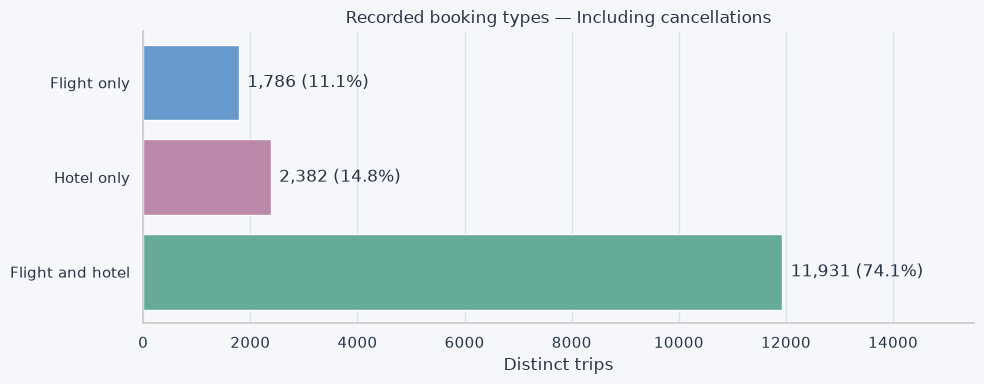

In [14]:
# identify available booking components for each distinct trip
# vorhandene buchungsbestandteile je eindeutiger reise erkennen
trips["has_flight_record"] = trips["trip_id"].isin(
    flights_clean["trip_id"]
)

trips["has_hotel_record"] = trips["trip_id"].isin(
    hotels_clean["trip_id"]
)

trips["booking_type"] = np.select(
    [
        trips["has_flight_record"] & trips["has_hotel_record"],
        trips["has_flight_record"] & ~trips["has_hotel_record"],
        ~trips["has_flight_record"] & trips["has_hotel_record"],
    ],
    [
        "Flight and hotel",
        "Flight only",
        "Hotel only",
    ],
    default="No booking details",
)

# summarise booking types, counting each trip once
# buchungsarten zusammenfassen, jede reise einmal zählen
booking_type_order = [
    "Flight only",
    "Hotel only",
    "Flight and hotel",
    "No booking details",
]

booking_type_counts = (
    trips["booking_type"]
    .value_counts()
    .reindex(booking_type_order, fill_value=0)
    .rename_axis("booking_type")
    .reset_index(name="trips")
)

booking_type_counts["share_pct"] = (
    booking_type_counts["trips"] / len(trips) * 100
)

if booking_type_counts["trips"].sum() != len(trips):
    raise ValueError("Trip counts do not match.")

display(style_overview(
    booking_type_counts,
    "Trips — Recorded booking types including cancellations",
    {
        "trips": "{:,.0f}",
        "share_pct": "{:.1f}%",
    },
))

# visualise booking types with available records
# buchungsarten mit vorhandenen datensätzen grafisch darstellen
plot_data = booking_type_counts.loc[
    booking_type_counts["trips"].gt(0)
]

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(
    plot_data["booking_type"],
    plot_data["trips"],
    color=[
        COLORS["blue"],
        COLORS["lavender"],
        COLORS["mint"],
        COLORS["orange"],
    ][:len(plot_data)],
)

ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.1f}%)"
        for count, share in zip(
            plot_data["trips"],
            plot_data["share_pct"],
        )
    ],
    padding=6,
    color=COLORS["text"],
)

ax.set(
    title="Recorded booking types — Including cancellations",
    xlabel="Distinct trips",
    ylabel="",
)

ax.invert_yaxis()
ax.set_xlim(0, plot_data["trips"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## 2.10 Booking-type shares per user
## 2.10 Anteile der Buchungsarten je Nutzer

Calculate the percentage of each user's distinct trips containing
a flight only, a hotel only, or both.

Trips with recorded cancellations remain included.
The percentages describe recorded booking components, not completed
travel. Users without trips receive missing percentages rather than 0%.

Je Nutzer den Anteil der eindeutigen Reisen mit ausschließlich
Flug, ausschließlich Hotel oder beidem berechnen.

Reisen mit verzeichneter Stornierung bleiben enthalten.
Die Anteile beschreiben erfasste Buchungsbestandteile, keine
durchgeführten Reisen. Nutzer ohne Reisen erhalten fehlende
Prozentwerte statt 0 %.

booking_type,users_with_this_booking_type,average_share_pct
Flight only,"1,552",11.5%
Hotel only,"1,988",17.3%
Flight and hotel,"4,939",71.2%


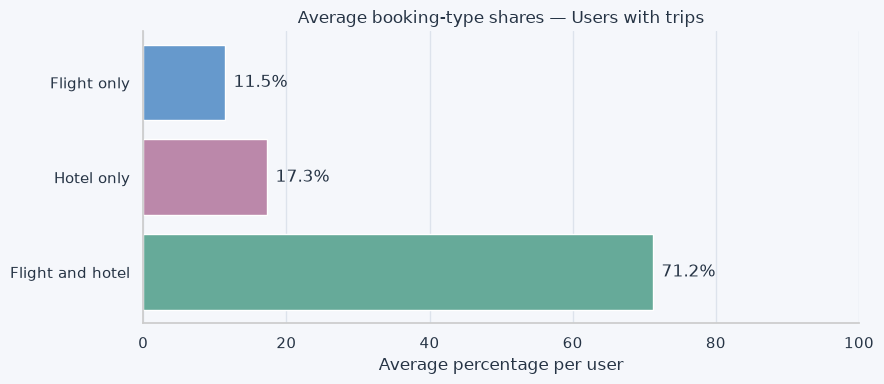

User-level booking-type shares passed.


In [15]:
# count booking types per user
# buchungsarten je nutzer zählen
booking_types = [
    "Flight only",
    "Hotel only",
    "Flight and hotel",
]

if not trips["booking_type"].isin(booking_types).all():
    raise ValueError("Resolve trips with unknown booking types first.")

user_booking_type_counts = (
    pd.crosstab(
        trips["user_id"],
        trips["booking_type"],
    )
    .reindex(columns=booking_types, fill_value=0)
)

# convert counts to percentages within each user
# anzahlwerte in anteile innerhalb jedes nutzers umrechnen
share_names = {
    "Flight only": "flight_only_trip_share_pct",
    "Hotel only": "hotel_only_trip_share_pct",
    "Flight and hotel": "flight_hotel_trip_share_pct",
}

user_booking_type_shares = (
    user_booking_type_counts
    .div(user_booking_type_counts.sum(axis=1), axis=0)
    .mul(100)
    .rename(columns=share_names)
    .reset_index()
)

share_columns = list(share_names.values())

user_features = (
    user_features
    .drop(columns=share_columns, errors="ignore")
    .merge(
        user_booking_type_shares,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# shares must total 100% for users with trips
# anteile müssen bei nutzern mit reisen zusammen 100 % ergeben
has_trips = user_features["trip_count"].gt(0)
known_shares = user_features.loc[has_trips, share_columns]

if (
    len(user_features) != len(users_clean)
    or known_shares.isna().any().any()
    or not np.allclose(
        known_shares.sum(axis=1).to_numpy(dtype=float),
        100,
    )
    or user_features.loc[
        ~has_trips, share_columns
    ].notna().any().any()
):
    raise ValueError("Check the booking-type percentages.")

# summarise the user-level percentages
# anteile auf nutzerebene zusammenfassen
booking_type_summary = pd.DataFrame({
    "booking_type": booking_types,
    "users_with_this_booking_type": [
        int(user_booking_type_counts[name].gt(0).sum())
        for name in booking_types
    ],
    "average_share_pct": [
        known_shares[share_names[name]].mean()
        for name in booking_types
    ],
})

display(style_overview(
    booking_type_summary,
    "Users with trips — Booking-type overview",
    {
        "users_with_this_booking_type": "{:,.0f}",
        "average_share_pct": "{:.1f}%",
    },
))

# visualise averages with equal weight for each user
# durchschnitte mit gleicher gewichtung jedes nutzers darstellen
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    booking_type_summary["booking_type"],
    booking_type_summary["average_share_pct"],
    color=[
        COLORS["blue"],
        COLORS["lavender"],
        COLORS["mint"],
    ],
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in booking_type_summary["average_share_pct"]
    ],
    padding=6,
    color=COLORS["text"],
)

ax.set(
    title="Average booking-type shares — Users with trips",
    xlabel="Average percentage per user",
    ylabel="",
    xlim=(0, 100),
)

ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print("User-level booking-type shares passed.")

### Result
### Ergebnis

Among the 5,542 users with trips, 4,939 have at least one trip
with both a flight and a hotel record. Flight-only trips appear
for 1,552 users, and hotel-only trips for 1,988 users.

Users may appear in multiple categories. These counts must
therefore not be added together.

The average individual booking-type shares are 11.5% flight only,
17.3% hotel only and 71.2% flight and hotel. Each user with trips
has equal weight. Trips with recorded cancellations remain included.

Von den 5.542 Nutzern mit Reisen haben 4.939 mindestens eine Reise
mit Flug- und Hoteldatensatz. Reine Flugbuchungen kommen bei
1.552 Nutzern vor, reine Hotelbuchungen bei 1.988 Nutzern.

Nutzer können in mehreren Kategorien vorkommen. Die Nutzerzahlen
dürfen deshalb nicht addiert werden.

Die durchschnittlichen individuellen Buchungsanteile betragen
11,5 % nur Flug, 17,3 % nur Hotel und 71,2 % Flug und Hotel.
Jeder Nutzer mit Reisen wird gleich gewichtet. Reisen mit
verzeichneter Stornierung bleiben berücksichtigt.

## 2.11 Discounted bookings per user
## 2.11 Rabattierte Buchungen je Nutzer

Calculate the percentage of flight and hotel bookings with
a discount, separately for each user.

Use booking sessions without a cancellation flag. A booking remains
included if it was subsequently cancelled; the cancellation session
itself does not count as another booking.

The seven bookings outside the filtered period are excluded because
their original discount information is unavailable in the filtered data.
Users without relevant booking sessions receive missing percentages.

Je Nutzer den Anteil rabattierter Flug- und Hotelbuchungen
getrennt berechnen.

Buchungssessions ohne Stornierungskennzeichnung verwenden.
Eine später stornierte Buchung bleibt berücksichtigt; die
Stornierungssession selbst zählt nicht als weitere Buchung.

Die sieben Buchungen außerhalb des gefilterten Zeitraums werden
ausgeschlossen, da ihre ursprünglichen Rabattinformationen in den
gefilterten Daten fehlen. Nutzer ohne entsprechende Buchungssessions
erhalten fehlende Prozentwerte.

In [16]:
# select original booking sessions within the filtered data
# ursprüngliche buchungssessions in den gefilterten daten auswählen
original_booking_sessions = sessions_clean.loc[
    sessions_clean["cancellation"].eq(False)
    & sessions_clean["trip_id"].notna()
    & (
        sessions_clean["flight_booked"].eq(True)
        | sessions_clean["hotel_booked"].eq(True)
    )
].copy()

if original_booking_sessions["trip_id"].duplicated().any():
    raise ValueError("Multiple booking sessions found for one trip.")

discount_overview_rows = []

for booking_kind in ["flight", "hotel"]:
    booked_column = f"{booking_kind}_booked"
    discount_column = f"{booking_kind}_discount"

    relevant_bookings = original_booking_sessions.loc[
        original_booking_sessions[booked_column].eq(True),
        ["user_id", discount_column],
    ]

    # discount indicators must be known for the selected bookings
    # rabattkennzeichnungen müssen für diese buchungen bekannt sein
    if (
        relevant_bookings[discount_column].isna().any()
        or not relevant_bookings[discount_column]
            .isin([True, False]).all()
    ):
        raise ValueError("Check the booking discount indicators.")

    count_column = f"{booking_kind}_booking_count_with_discount_data"
    share_column = f"{booking_kind}_discount_booking_share_pct"

    user_discount_metrics = (
        relevant_bookings
        .groupby("user_id")
        .agg(
            booking_count=(discount_column, "size"),
            discounted_booking_count=(discount_column, "sum"),
        )
    )

    user_discount_metrics[share_column] = (
        user_discount_metrics["discounted_booking_count"]
        / user_discount_metrics["booking_count"]
        * 100
    )

    user_discount_metrics = (
        user_discount_metrics
        .rename(columns={"booking_count": count_column})
        [[count_column, share_column]]
        .reset_index()
    )

    user_features = (
        user_features
        .drop(
            columns=[count_column, share_column],
            errors="ignore",
        )
        .merge(
            user_discount_metrics,
            on="user_id",
            how="left",
            validate="one_to_one",
        )
    )

    # no relevant bookings: count zero, percentage remains unknown
    # keine entsprechenden buchungen: anzahl null, anteil bleibt unbekannt
    user_features[count_column] = (
        user_features[count_column].fillna(0).astype("Int64")
    )

    known_shares = user_features[share_column].dropna()

    if (
        len(user_features) != len(users_clean)
        or user_features[count_column].sum() != len(relevant_bookings)
        or not known_shares.between(0, 100).all()
    ):
        raise ValueError("Check the user-level discount metrics.")

    discount_overview_rows.append({
        "booking_type": booking_kind.title(),
        "bookings_checked": len(relevant_bookings),
        "bookings_with_discount": int(
            relevant_bookings[discount_column].sum()
        ),
        "users_with_known_percentage": len(known_shares),
        "average_user_percentage": known_shares.mean(),
    })

discount_booking_overview = pd.DataFrame(discount_overview_rows)

display(style_overview(
    discount_booking_overview,
    "Users — Bookings with a discount",
    {
        "bookings_checked": "{:,.0f}",
        "bookings_with_discount": "{:,.0f}",
        "users_with_known_percentage": "{:,.0f}",
        "average_user_percentage": "{:.1f}%",
    },
))

print("User-level discount booking percentages passed.")

booking_type,bookings_checked,bookings_with_discount,users_with_known_percentage,average_user_percentage
Flight,"13,710","1,970","5,178",15.0%
Hotel,"14,309","1,929","5,401",13.8%


User-level discount booking percentages passed.


### Result
### Ergebnis

Discount information is available for 13,710 flight bookings and
14,309 hotel bookings. Of these, 1,970 flight bookings and
1,929 hotel bookings have a recorded discount.

The average individual percentage of discounted bookings is
15.0% for flights and 13.8% for hotels. Each user with relevant
booking data has equal weight in the respective average.

These features describe recorded discount usage. They do not
establish that users actively searched for discounts.

Rabattinformationen liegen für 13.710 Flugbuchungen und
14.309 Hotelbuchungen vor. Davon haben 1.970 Flugbuchungen
und 1.929 Hotelbuchungen einen verzeichneten Rabatt.

Der durchschnittliche individuelle Anteil rabattierter Buchungen
beträgt 15,0 % bei Flügen und 13,8 % bei Hotels. Jeder Nutzer mit
entsprechenden Buchungsdaten wird im jeweiligen Durchschnitt
gleich gewichtet.

Die Merkmale beschreiben die verzeichnete Rabattnutzung.
Sie belegen nicht, dass Nutzer aktiv nach Rabatten gesucht haben.

## 2.12 Average discount rate per user
## 2.12 Durchschnittliche Rabatthöhe je Nutzer

Calculate each user's average recorded discount rate separately
for flight and hotel bookings. Only discounted booking sessions
are included.

Bookings without a discount do not enter this average.
Users without recorded discounted bookings receive missing values.
Cancellation sessions are excluded.

Je Nutzer die durchschnittliche dokumentierte Rabatthöhe für
Flug- und Hotelbuchungen getrennt berechnen. Berücksichtigt
werden ausschließlich rabattierte Buchungssessions.

Buchungen ohne Rabatt fließen nicht in diesen Durchschnitt ein.
Nutzer ohne dokumentierte rabattierte Buchungen erhalten fehlende
Werte. Stornierungssessions werden ausgeschlossen.

In [17]:
# calculate average discount rates for discounted bookings only
# durchschnittliche rabatthöhen nur aus rabattierten buchungen berechnen
discount_rate_rows = []

for booking_kind in ["flight", "hotel"]:
    booked_column = f"{booking_kind}_booked"
    discount_column = f"{booking_kind}_discount"
    amount_column = f"{booking_kind}_discount_amount"
    feature_column = f"avg_{booking_kind}_discount_pct"

    discounted_bookings = original_booking_sessions.loc[
        original_booking_sessions[booked_column].eq(True)
        & original_booking_sessions[discount_column].eq(True),
        ["user_id", amount_column],
    ].copy()

    # validate recorded rates before calculating user averages
    # dokumentierte rabattsätze vor der berechnung prüfen
    rates = pd.to_numeric(
        discounted_bookings[amount_column],
        errors="coerce",
    )

    if rates.isna().any() or not rates.between(0, 1).all():
        raise ValueError("Check discount rates on discounted bookings.")

    discounted_bookings[feature_column] = rates * 100

    user_discount_rates = (
        discounted_bookings
        .groupby("user_id")[feature_column]
        .mean()
        .reset_index()
    )

    user_features = (
        user_features
        .drop(columns=[feature_column], errors="ignore")
        .merge(
            user_discount_rates,
            on="user_id",
            how="left",
            validate="one_to_one",
        )
    )

    if len(user_features) != len(users_clean):
        raise ValueError("The user count changed.")

    known_rates = user_features[feature_column].dropna()

    discount_rate_rows.append({
        "booking_type": booking_kind.title(),
        "discounted_bookings": len(discounted_bookings),
        "users_with_known_rate": len(known_rates),
        "minimum_user_average": known_rates.min(),
        "median_user_average": known_rates.median(),
        "maximum_user_average": known_rates.max(),
    })

discount_rate_overview = pd.DataFrame(discount_rate_rows)

display(style_overview(
    discount_rate_overview,
    "Users — Average discount rates on discounted bookings",
    {
        "discounted_bookings": "{:,.0f}",
        "users_with_known_rate": "{:,.0f}",
        "minimum_user_average": "{:.1f}%",
        "median_user_average": "{:.1f}%",
        "maximum_user_average": "{:.1f}%",
    },
))

print("User-level average discount rates passed.")

booking_type,discounted_bookings,users_with_known_rate,minimum_user_average,median_user_average,maximum_user_average
Flight,"1,970","1,718",5.0%,10.0%,50.0%
Hotel,"1,929","1,660",5.0%,10.0%,45.0%


User-level average discount rates passed.


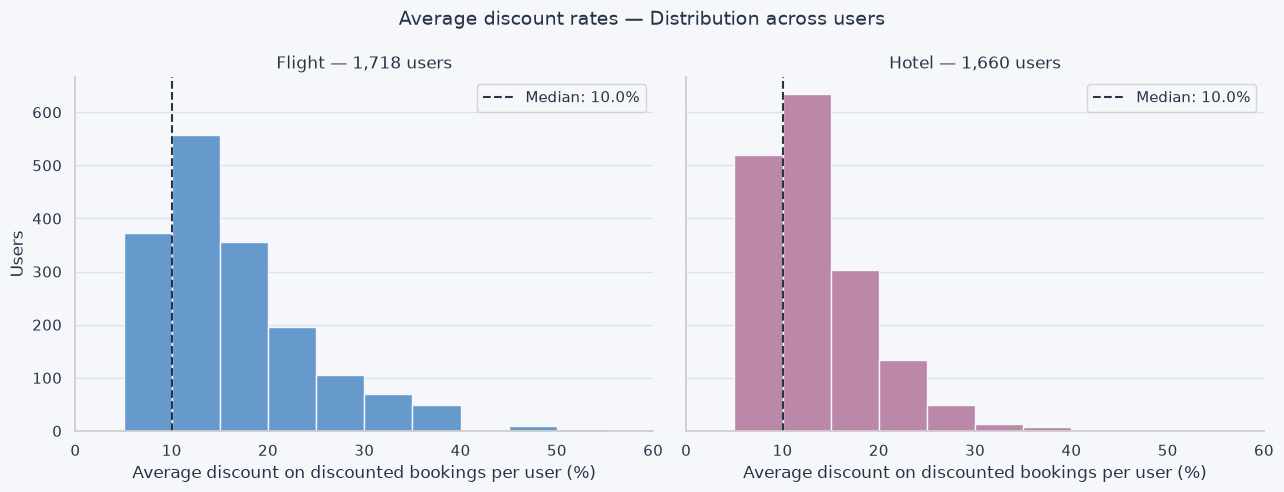

In [18]:
# visualise average discount rates per user
# durchschnittliche rabatthöhen je nutzer darstellen
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True,
)

chart_settings = [
    (
        axes[0],
        "avg_flight_discount_pct",
        "Flight",
        COLORS["blue"],
    ),
    (
        axes[1],
        "avg_hotel_discount_pct",
        "Hotel",
        COLORS["lavender"],
    ),
]

for ax, column, title, color in chart_settings:
    known_rates = user_features[column].dropna()

    ax.hist(
        known_rates.to_numpy(dtype=float),
        bins=np.arange(0, 61, 5),
        color=color,
        edgecolor=COLORS["background"],
    )

    ax.axvline(
        known_rates.median(),
        color=COLORS["text"],
        linestyle="--",
        linewidth=1.5,
        label=f"Median: {known_rates.median():.1f}%",
    )

    ax.set(
        title=f"{title} — {len(known_rates):,} users",
        xlabel="Average discount on discounted bookings per user (%)",
        xlim=(0, 60),
    )

    ax.set_xticks(range(0, 61, 10))
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    ax.legend()

axes[0].set_ylabel("Users")

fig.suptitle(
    "Average discount rates — Distribution across users",
    fontsize=14,
)

fig.tight_layout()
plt.show()

### Result
### Ergebnis

Average discount rates could be calculated for 1,718 users with
discounted flight bookings and 1,660 users with discounted hotel
bookings in the filtered data.

Individual user averages range from 5% to 50% for flights and
from 5% to 45% for hotels. The median user average is 10% for both.

Only discounted bookings enter these averages. Users without
recorded discounted bookings retain missing values.

Für 1.718 Nutzer mit rabattierten Flugbuchungen und 1.660 Nutzer
mit rabattierten Hotelbuchungen konnten durchschnittliche
Rabatthöhen anhand der gefilterten Daten berechnet werden.

Die individuellen Nutzerdurchschnitte reichen bei Flügen von
5 % bis 50 % und bei Hotels von 5 % bis 45 %. Der Median der
Nutzerdurchschnitte beträgt jeweils 10 %.

Nur rabattierte Buchungen fließen in diese Durchschnitte ein.
Nutzer ohne dokumentierte rabattierte Buchungen behalten
fehlende Werte.

## 2.13 Checked baggage bookings
## 2.13 Buchungen mit Aufgabegepäck

Answer two questions:

- How many users book checked baggage on none, some or all
  of their flight bookings?
- How many checked bags are recorded per flight booking?

Users without flight bookings are reported separately.
Each flight booking counts once, including bookings with a
recorded cancellation. These are booking records, not proof
of baggage actually transported.

Zwei Fragen beantworten:

- Wie viele Nutzer buchen bei keiner, einigen oder allen
  Flugbuchungen Aufgabegepäck?
- Wie viele Gepäckstücke sind je Flugbuchung erfasst?

Nutzer ohne Flugbuchungen werden separat ausgewiesen.
Jede Flugbuchung zählt einmal, einschließlich Buchungen mit
verzeichneter Stornierung. Beschrieben werden Buchungsdaten,
kein tatsächlich transportiertes Gepäck.

In [19]:
# assign flight bookings to users
# flugbuchungen den nutzern zuordnen
flight_bookings = flights_clean.merge(
    trips[["trip_id", "user_id"]],
    on="trip_id",
    how="left",
    validate="one_to_one",
)

if (
    len(flight_bookings) != len(flights_clean)
    or flight_bookings["user_id"].isna().any()
):
    raise ValueError("Check the flight-to-user assignments.")

flight_bookings["has_checked_baggage"] = (
    flight_bookings["checked_bags"].gt(0)
)

# calculate understandable counts per user
# verständliche anzahlwerte je nutzer berechnen
user_baggage_metrics = (
    flight_bookings
    .groupby("user_id")
    .agg(
        flight_trip_count=("trip_id", "size"),
        flight_with_baggage_count=("has_checked_baggage", "sum"),
        total_checked_bags=("checked_bags", "sum"),
    )
    .reset_index()
)

# replace the previous baggage features
# bisherige gepäckmerkmale ersetzen
baggage_columns = [
    "flight_trip_count",
    "flight_with_baggage_count",
    "total_checked_bags",
]

user_features = (
    user_features
    .drop(
        columns=baggage_columns + [
            "flight_with_baggage_share_pct",
            "checked_bags_per_seat",
        ],
        errors="ignore",
    )
    .merge(
        user_baggage_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

for column in baggage_columns:
    user_features[column] = (
        user_features[column].fillna(0).astype("Int64")
    )

if (
    len(user_features) != len(users_clean)
    or user_features["flight_trip_count"].sum()
        != len(flights_clean)
    or user_features["total_checked_bags"].sum()
        != flights_clean["checked_bags"].sum()
    or user_features["flight_with_baggage_count"].gt(
        user_features["flight_trip_count"]
    ).any()
):
    raise ValueError("Check the baggage counts.")

# classify users with flight bookings for the chart
# nutzer mit flugbuchungen für die grafik einordnen
baggage_users = user_features.loc[
    user_features["flight_trip_count"].gt(0)
].copy()

baggage_users["baggage_pattern"] = np.select(
    [
        baggage_users["flight_with_baggage_count"].eq(0),
        baggage_users["flight_with_baggage_count"].eq(
            baggage_users["flight_trip_count"]
        ),
    ],
    [
        "Never booked checked baggage",
        "Always booked checked baggage",
    ],
    default="Sometimes booked checked baggage",
)

user_pattern_order = [
    "Never booked checked baggage",
    "Sometimes booked checked baggage",
    "Always booked checked baggage",
]

baggage_user_counts = (
    baggage_users["baggage_pattern"]
    .value_counts()
    .reindex(user_pattern_order, fill_value=0)
)

# group baggage quantities per flight booking
# gepäckmenge je flugbuchung gruppieren
bag_quantity_order = [
    "No checked bags",
    "1 checked bag",
    "2 checked bags",
    "3 or more checked bags",
]

flight_bookings["baggage_quantity_group"] = np.select(
    [
        flight_bookings["checked_bags"].eq(0),
        flight_bookings["checked_bags"].eq(1),
        flight_bookings["checked_bags"].eq(2),
    ],
    bag_quantity_order[:3],
    default=bag_quantity_order[3],
)

baggage_booking_counts = (
    flight_bookings["baggage_quantity_group"]
    .value_counts()
    .reindex(bag_quantity_order, fill_value=0)
)

users_without_flights = int(
    user_features["flight_trip_count"].eq(0).sum()
)

display(style_overview(
    pd.DataFrame({
        "metric": [
            "Users with flight bookings",
            "Users without flight bookings",
            "Flight bookings",
        ],
        "count": [
            len(baggage_users),
            users_without_flights,
            len(flight_bookings),
        ],
    }),
    "Checked baggage — Data overview",
    {"count": "{:,.0f}"},
))

print("User-level baggage counts passed.")

metric,count
Users with flight bookings,"5,180"
Users without flight bookings,818
Flight bookings,"13,717"


User-level baggage counts passed.


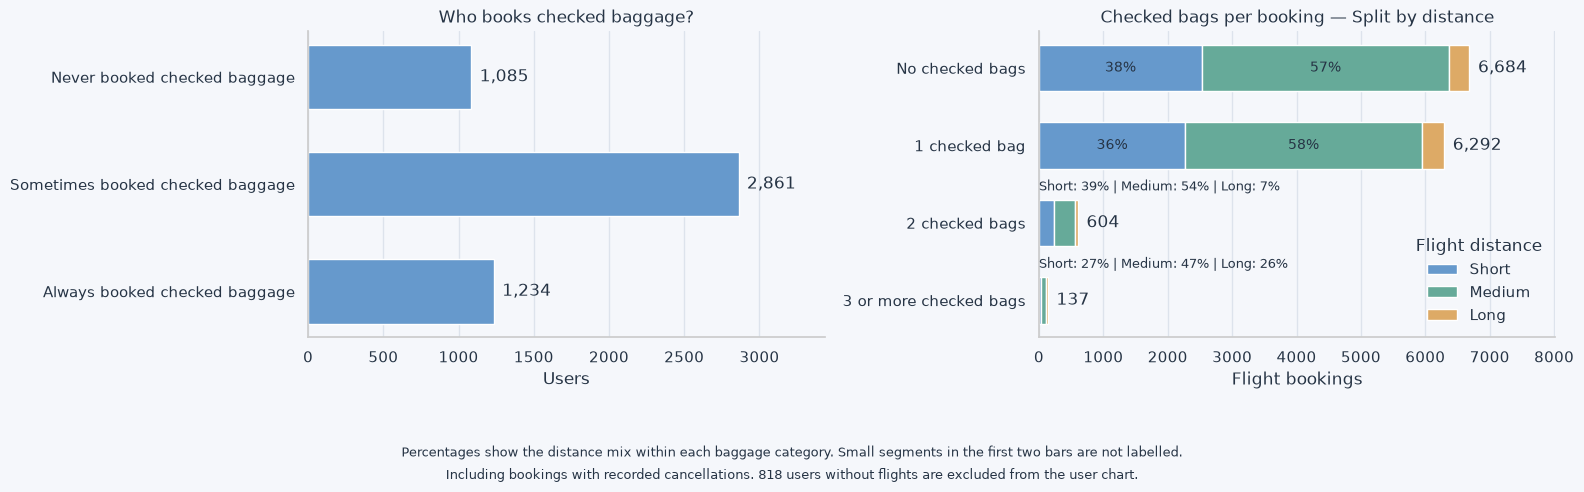

In [20]:
# split each baggage category by flight distance
# jede gepäckkategorie nach flugdistanz aufteilen
distance_order = ["Short", "Medium", "Long"]

if not flight_bookings["flight_distance_group"].isin(
    distance_order
).all():
    raise ValueError("Check the flight distance groups.")

baggage_by_distance = (
    pd.crosstab(
        flight_bookings["baggage_quantity_group"],
        flight_bookings["flight_distance_group"],
    )
    .reindex(
        index=bag_quantity_order,
        columns=distance_order,
        fill_value=0,
    )
)

category_totals = baggage_by_distance.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# left: each user counts once
# links: jeder nutzer zählt einmal
bars = axes[0].barh(
    baggage_user_counts.index,
    baggage_user_counts.to_numpy(dtype=int),
    color=COLORS["blue"],
    height=0.6,
)

axes[0].bar_label(
    bars,
    labels=[
        f"{int(count):,}"
        for count in baggage_user_counts
    ],
    padding=6,
    color=COLORS["text"],
)

axes[0].set(
    title="Who books checked baggage?",
    xlabel="Users",
    ylabel="",
    xlim=(0, baggage_user_counts.max() * 1.2),
)

# right: divide flight bookings into distance groups
# rechts: flugbuchungen nach distanzgruppen unterteilen
distance_colors = [
    COLORS["blue"],
    COLORS["mint"],
    COLORS["orange"],
]

left_positions = np.zeros(len(bag_quantity_order))

for distance_group, color in zip(
    distance_order,
    distance_colors,
):
    counts = baggage_by_distance[
        distance_group
    ].to_numpy(dtype=int)

    axes[1].barh(
        bag_quantity_order,
        counts,
        left=left_positions,
        color=color,
        height=0.6,
        label=distance_group,
    )

    # label larger segments inside the first two bars
    # größere segmente innerhalb der ersten beiden balken beschriften
    for position, count in enumerate(counts):
        total = category_totals.iloc[position]
        percentage = count / total * 100 if total else 0

        if percentage >= 8 and position < 2:
            axes[1].text(
                left_positions[position] + count / 2,
                position,
                f"{percentage:.0f}%",
                ha="center",
                va="center",
                color=COLORS["text"],
                fontsize=10,
            )

    left_positions += counts

# use one shared label above each short bar
# eine gemeinsame beschriftung über jedem kurzen balken
for position in [2, 3]:
    total = category_totals.iloc[position]

    if total > 0:
        label_parts = [
            (
                f"{group}: "
                f"{baggage_by_distance.iloc[position][group] / total * 100:.0f}%"
            )
            for group in distance_order
        ]

        axes[1].text(
            0,
            position - 0.38,
            " | ".join(label_parts),
            ha="left",
            va="bottom",
            color=COLORS["text"],
            fontsize=9,
        )

# show total bookings beside each bar
# gesamte buchungsanzahl neben jedem balken zeigen
for position, total in enumerate(category_totals):
    axes[1].text(
        total + category_totals.max() * 0.02,
        position,
        f"{int(total):,}",
        ha="left",
        va="center",
        color=COLORS["text"],
    )

axes[1].set(
    title="Checked bags per booking — Split by distance",
    xlabel="Flight bookings",
    ylabel="",
    xlim=(0, category_totals.max() * 1.2),
)

axes[1].legend(
    title="Flight distance",
    loc="lower right",
    frameon=False,
)

for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.17, 1, 1))

fig.text(
    0.5,
    0.07,
    "Percentages show the distance mix within each baggage category. "
    "Small segments in the first two bars are not labelled.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.025,
    "Including bookings with recorded cancellations. "
    f"{users_without_flights:,} users without flights "
    "are excluded from the user chart.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

### Result
### Ergebnis

Of the 5,180 users with flight bookings:

- 1,085 never booked checked baggage.
- 2,861 booked checked baggage on some flight bookings.
- 1,234 booked checked baggage on every flight booking.

The 818 users without flight bookings are excluded from these
categories. “Never” and “always” refer only to the recorded bookings.

Of the 13,717 flight bookings, 6,684 have no checked bags,
6,292 have one, 604 have two, and 137 have three or more.

Among bookings with three or more checked bags, 26% belong to
the Long distance group. This describes the distance mix within
that baggage category, not the percentage of long-distance
bookings with three or more bags.

Bookings with recorded cancellations remain included.
The results describe booking behaviour, not baggage actually
transported or confirmed interest in a free-baggage benefit.

Von den 5.180 Nutzern mit Flugbuchungen haben:

- 1.085 nie Aufgabegepäck gebucht.
- 2.861 bei einigen Flugbuchungen Aufgabegepäck gebucht.
- 1.234 bei jeder Flugbuchung Aufgabegepäck gebucht.

Die 818 Nutzer ohne Flugbuchungen sind in diesen Kategorien
nicht enthalten. „Nie“ und „immer“ beziehen sich ausschließlich
auf die erfassten Buchungen.

Von den 13.717 Flugbuchungen enthalten 6.684 kein Aufgabegepäck,
6.292 ein Gepäckstück, 604 zwei und 137 mindestens drei Gepäckstücke.

Bei Buchungen mit mindestens drei Gepäckstücken entfallen 26 %
auf die Distanzgruppe Long. Das beschreibt die Distanzverteilung
innerhalb dieser Gepäckkategorie, nicht den Anteil der
Langstreckenbuchungen mit mindestens drei Gepäckstücken.

Buchungen mit verzeichneter Stornierung bleiben berücksichtigt.
Die Ergebnisse beschreiben Buchungsverhalten, kein tatsächlich
transportiertes Gepäck oder bestätigtes Interesse an einem
kostenlosen Gepäckstück.

## 2.14 Hotel bookings and length of stay
## 2.14 Hotelbuchungen und Aufenthaltsdauer

Count hotel bookings per user and calculate the average number
of nights from bookings with known cleaned night counts.

Known same-day stays count as zero nights. Unresolved night counts
remain missing and are excluded from the average. Their number
is retained separately.

Each hotel booking counts once, including bookings with recorded
cancellations. These features describe bookings, not completed stays.

Hotelbuchungen je Nutzer zählen und die durchschnittliche Anzahl
der Nächte aus Buchungen mit bekannten bereinigten Nächtewerten
berechnen.

Bekannte Aufenthalte am selben Tag zählen als null Nächte.
Ungeklärte Nächtewerte bleiben fehlend und werden beim Durchschnitt
ausgeschlossen. Ihre Anzahl wird separat festgehalten.

Jede Hotelbuchung zählt einmal, einschließlich Buchungen mit
verzeichneter Stornierung. Die Merkmale beschreiben Buchungen,
keine tatsächlich durchgeführten Aufenthalte.

In [21]:
# assign hotel bookings to users
# hotelbuchungen den nutzern zuordnen
hotel_bookings = hotels_clean.merge(
    trips[["trip_id", "user_id"]],
    on="trip_id",
    how="left",
    validate="one_to_one",
)

if (
    len(hotel_bookings) != len(hotels_clean)
    or hotel_bookings["user_id"].isna().any()
):
    raise ValueError("Check the hotel-to-user assignments.")

hotel_bookings["unknown_nights"] = (
    hotel_bookings["nights"].isna()
)

# aggregate hotel bookings and known nights per user
# hotelbuchungen und bekannte nächte je nutzer zusammenfassen
user_hotel_metrics = (
    hotel_bookings
    .groupby("user_id")
    .agg(
        hotel_trip_count=("trip_id", "size"),
        hotel_trips_with_unknown_nights=("unknown_nights", "sum"),
        avg_hotel_nights=("nights", "mean"),
    )
    .reset_index()
)

hotel_columns = [
    "hotel_trip_count",
    "hotel_trips_with_unknown_nights",
    "avg_hotel_nights",
]

user_features = (
    user_features
    .drop(columns=hotel_columns, errors="ignore")
    .merge(
        user_hotel_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# restore counts; leave unknown averages missing
# anzahlwerte ergänzen; unbekannte durchschnitte fehlend lassen
for column in [
    "hotel_trip_count",
    "hotel_trips_with_unknown_nights",
]:
    user_features[column] = (
        user_features[column].fillna(0).astype("Int64")
    )

has_hotels = user_features["hotel_trip_count"].gt(0)

has_known_nights = (
    user_features["hotel_trip_count"]
    > user_features["hotel_trips_with_unknown_nights"]
)

# validate counts and availability of user averages
# anzahlwerte und verfügbarkeit der nutzerdurchschnitte prüfen
if (
    len(user_features) != len(users_clean)
    or user_features["hotel_trip_count"].sum()
        != len(hotels_clean)
    or user_features["hotel_trips_with_unknown_nights"].sum()
        != hotels_clean["nights"].isna().sum()
    or not user_features["avg_hotel_nights"]
        .notna()
        .eq(has_known_nights)
        .all()
    or user_features["avg_hotel_nights"].dropna().lt(0).any()
):
    raise ValueError("Check the user-level hotel metrics.")

hotel_overview = pd.DataFrame({
    "metric": [
        "Hotel bookings",
        "Users with hotel bookings",
        "Users without hotel bookings",
        "Hotel bookings with unknown nights",
        "Users with at least one known night count",
        "Users with hotel bookings but no known night counts",
    ],
    "count": [
        len(hotel_bookings),
        int(has_hotels.sum()),
        int((~has_hotels).sum()),
        int(hotel_bookings["unknown_nights"].sum()),
        int(has_known_nights.sum()),
        int((has_hotels & ~has_known_nights).sum()),
    ],
})

display(style_overview(
    hotel_overview,
    "Users — Hotel bookings and available night counts",
    {"count": "{:,.0f}"},
))

print("User-level hotel metrics passed.")

metric,count
Hotel bookings,"14,313"
Users with hotel bookings,"5,402"
Users without hotel bookings,596
Hotel bookings with unknown nights,226
Users with at least one known night count,"5,387"
Users with hotel bookings but no known night counts,15


User-level hotel metrics passed.


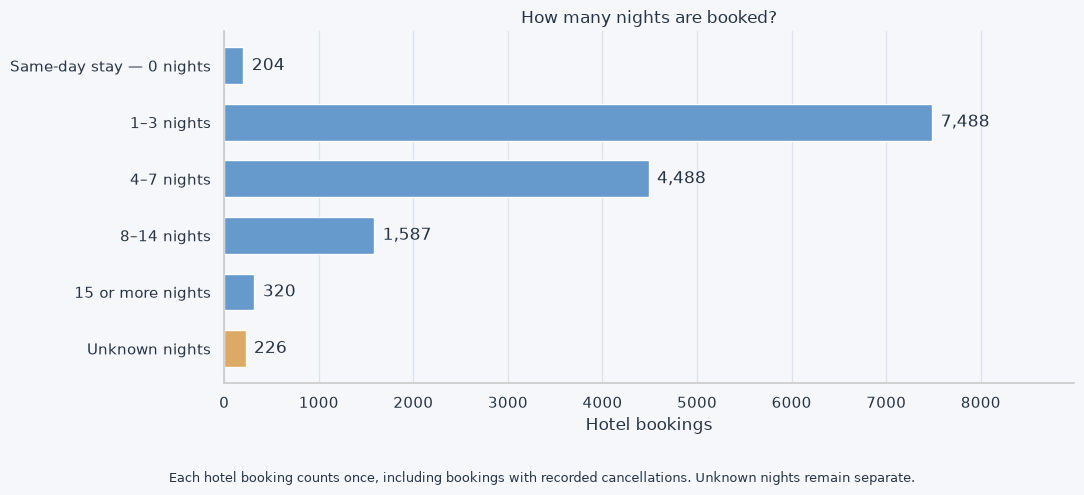

In [22]:
# group hotel bookings by their cleaned night counts
# hotelbuchungen nach ihren bereinigten nächtezahlen gruppieren
stay_order = [
    "Same-day stay — 0 nights",
    "1–3 nights",
    "4–7 nights",
    "8–14 nights",
    "15 or more nights",
    "Unknown nights",
]

hotel_bookings["stay_length_group"] = pd.cut(
    hotel_bookings["nights"],
    bins=[-0.5, 0.5, 3.5, 7.5, 14.5, np.inf],
    labels=stay_order[:-1],
).astype("string").fillna("Unknown nights")

stay_counts = (
    hotel_bookings["stay_length_group"]
    .value_counts()
    .reindex(stay_order, fill_value=0)
)

if stay_counts.sum() != len(hotel_bookings):
    raise ValueError("Not all hotel bookings were counted.")

bar_colors = [
    COLORS["blue"],
    COLORS["blue"],
    COLORS["blue"],
    COLORS["blue"],
    COLORS["blue"],
    COLORS["orange"],
]

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    stay_counts.index,
    stay_counts.to_numpy(dtype=int),
    color=bar_colors,
    height=0.65,
)

ax.bar_label(
    bars,
    labels=[f"{int(count):,}" for count in stay_counts],
    padding=6,
    color=COLORS["text"],
)

ax.set(
    title="How many nights are booked?",
    xlabel="Hotel bookings",
    ylabel="",
    xlim=(0, stay_counts.max() * 1.2),
)

ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.08, 1, 1))

fig.text(
    0.5,
    0.02,
    "Each hotel booking counts once, including bookings with recorded cancellations. "
    "Unknown nights remain separate.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

stay_length,1 room,2 rooms,3 rooms,4 rooms,total_bookings
Same-day stay — 0 nights,177,20,5,2,204
1–3 nights,"6,484",767,184,53,"7,488"
4–7 nights,"3,752",570,136,30,"4,488"
8–14 nights,"1,249",286,50,2,"1,587"
15 or more nights,248,60,12,0,320
Unknown nights,188,34,2,2,226


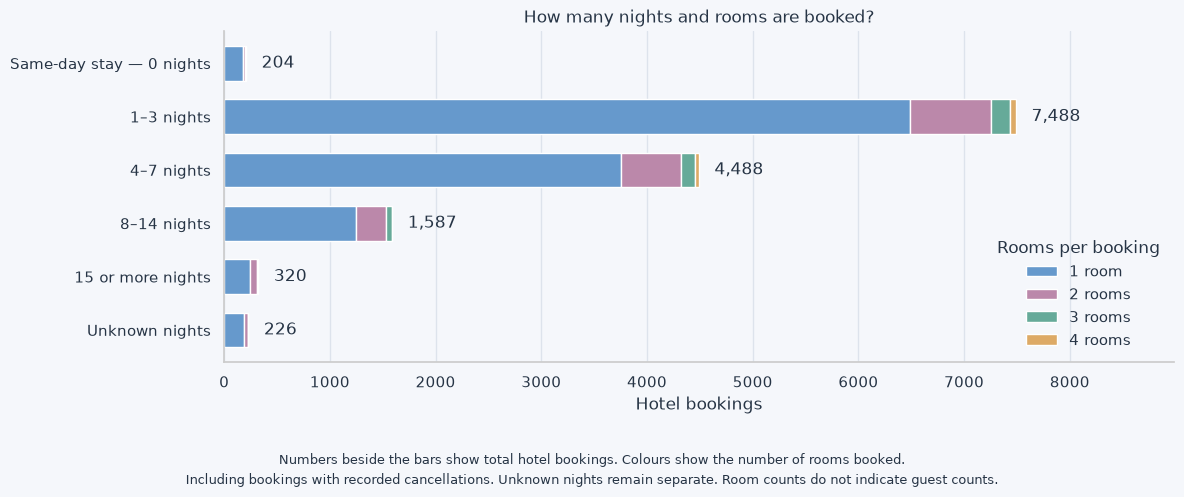

In [23]:
# group hotel bookings by cleaned night counts
# hotelbuchungen nach bereinigten nächtezahlen gruppieren
stay_order = [
    "Same-day stay — 0 nights",
    "1–3 nights",
    "4–7 nights",
    "8–14 nights",
    "15 or more nights",
    "Unknown nights",
]

hotel_bookings["stay_length_group"] = (
    pd.cut(
        hotel_bookings["nights"],
        bins=[-0.5, 0.5, 3.5, 7.5, 14.5, np.inf],
        labels=stay_order[:-1],
    )
    .astype("string")
    .fillna("Unknown nights")
)

room_order = [1, 2, 3, 4]

if not hotel_bookings["rooms"].isin(room_order).all():
    raise ValueError("Check the room counts.")

# count bookings for each combination of nights and rooms
# buchungen je kombination aus nächten und zimmern zählen
stays_by_rooms = (
    pd.crosstab(
        hotel_bookings["stay_length_group"],
        hotel_bookings["rooms"],
    )
    .reindex(
        index=stay_order,
        columns=room_order,
        fill_value=0,
    )
)

stay_totals = stays_by_rooms.sum(axis=1)

if stay_totals.sum() != len(hotel_bookings):
    raise ValueError("Not all hotel bookings were counted.")

# show exact counts alongside the visual comparison
# genaue anzahlwerte zusätzlich zum grafischen vergleich zeigen
room_summary = (
    stays_by_rooms
    .rename(columns={
        1: "1 room",
        2: "2 rooms",
        3: "3 rooms",
        4: "4 rooms",
    })
    .assign(total_bookings=stay_totals)
    .rename_axis("stay_length")
    .reset_index()
)

display(style_overview(
    room_summary,
    "Hotel bookings — Nights and rooms",
    {
        column: "{:,.0f}"
        for column in [
            "1 room",
            "2 rooms",
            "3 rooms",
            "4 rooms",
            "total_bookings",
        ]
    },
))

# split each stay-length bar by room count
# jeden aufenthaltsbalken nach zimmeranzahl unterteilen
fig, ax = plt.subplots(figsize=(12, 5))

room_colors = [
    COLORS["blue"],
    COLORS["lavender"],
    COLORS["mint"],
    COLORS["orange"],
]

left_positions = np.zeros(len(stay_order))

for room_count, color in zip(room_order, room_colors):
    counts = stays_by_rooms[room_count].to_numpy(dtype=int)

    ax.barh(
        stay_order,
        counts,
        left=left_positions,
        color=color,
        height=0.65,
        label=(
            "1 room"
            if room_count == 1
            else f"{room_count} rooms"
        ),
    )

    left_positions += counts

# label total bookings outside each bar
# gesamte buchungsanzahl außerhalb jedes balkens beschriften
for position, total in enumerate(stay_totals):
    ax.text(
        total + stay_totals.max() * 0.02,
        position,
        f"{int(total):,}",
        ha="left",
        va="center",
        color=COLORS["text"],
    )

ax.set(
    title="How many nights and rooms are booked?",
    xlabel="Hotel bookings",
    ylabel="",
    xlim=(0, stay_totals.max() * 1.2),
)

ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

ax.legend(
    title="Rooms per booking",
    loc="lower right",
    frameon=False,
)

fig.tight_layout(rect=(0, 0.12, 1, 1))

fig.text(
    0.5,
    0.055,
    "Numbers beside the bars show total hotel bookings. "
    "Colours show the number of rooms booked.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.015,
    "Including bookings with recorded cancellations. "
    "Unknown nights remain separate. Room counts do not indicate guest counts.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

### Result
### Ergebnis

The most common stay length is 1–3 nights (7,488 bookings),
followed by 4–7 nights (4,488 bookings).

One room is the most common room count in every stay-length group.
The most frequent combination is one room for 1–3 nights,
with 6,484 bookings.

The 204 known same-day stays and 226 bookings with unresolved
night counts remain separate. Room counts do not establish
the number or relationship of guests.

Bookings with recorded cancellations remain included.
The chart counts hotel bookings, not users or completed stays.

Die häufigste Aufenthaltsdauer beträgt 1–3 Nächte (7.488 Buchungen),
gefolgt von 4–7 Nächten (4.488 Buchungen).

In jeder Aufenthaltsgruppe wird am häufigsten ein Zimmer gebucht.
Die häufigste Kombination ist ein Zimmer für 1–3 Nächte
mit 6.484 Buchungen.

Die 204 bekannten Aufenthalte am selben Tag und die 226 Buchungen
mit ungeklärter Nächtezahl bleiben separat ausgewiesen.
Die Zimmeranzahl belegt weder die Anzahl noch die Beziehung
der Gäste untereinander.

Buchungen mit verzeichneter Stornierung bleiben berücksichtigt.
Die Grafik zählt Hotelbuchungen, keine Nutzer oder tatsächlich
durchgeführten Aufenthalte.

## 2.15 Booking size per user
## 2.15 Buchungsgröße je Nutzer

Calculate the average number of seats per flight booking and
rooms per hotel booking for each user.

Each booking counts once, including bookings with recorded
cancellations. Users without the relevant booking type receive
missing averages.

Booking size does not establish whether the travellers are
individuals, couples, families or colleagues.

Je Nutzer die durchschnittliche Sitzplatzanzahl pro Flugbuchung
und Zimmeranzahl pro Hotelbuchung berechnen.

Jede Buchung zählt einmal, einschließlich Buchungen mit
verzeichneter Stornierung. Nutzer ohne die entsprechende
Buchungsart erhalten fehlende Durchschnittswerte.

Die Buchungsgröße belegt nicht, ob Einzelpersonen, Paare,
Familien oder Kollegen reisen.

In [24]:
# calculate average seats and rooms per booking for each user
# durchschnittliche sitzplätze und zimmer je buchung und nutzer berechnen
user_seat_metrics = (
    flight_bookings
    .groupby("user_id")["seats"]
    .mean()
    .rename("avg_seats_per_flight_booking")
    .reset_index()
)

user_room_metrics = (
    hotel_bookings
    .groupby("user_id")["rooms"]
    .mean()
    .rename("avg_rooms_per_hotel_booking")
    .reset_index()
)

size_columns = [
    "avg_seats_per_flight_booking",
    "avg_rooms_per_hotel_booking",
]

user_features = (
    user_features
    .drop(columns=size_columns, errors="ignore")
    .merge(
        user_seat_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        user_room_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# validate coverage and plausible ranges
# abdeckung und plausible wertebereiche prüfen
seats_known = user_features[
    "avg_seats_per_flight_booking"
].notna()

rooms_known = user_features[
    "avg_rooms_per_hotel_booking"
].notna()

if (
    len(user_features) != len(users_clean)
    or not seats_known.eq(
        user_features["flight_trip_count"].gt(0)
    ).all()
    or not rooms_known.eq(
        user_features["hotel_trip_count"].gt(0)
    ).all()
    or not user_features[
        "avg_seats_per_flight_booking"
    ].dropna().between(1, 8).all()
    or not user_features[
        "avg_rooms_per_hotel_booking"
    ].dropna().between(1, 4).all()
):
    raise ValueError("Check the user-level booking sizes.")

# preview the new features alongside booking counts
# neue merkmale zusammen mit den buchungsanzahlen anzeigen
display(style_overview(
    user_features[[
        "user_id",
        "flight_trip_count",
        "avg_seats_per_flight_booking",
        "hotel_trip_count",
        "avg_rooms_per_hotel_booking",
    ]].head(10),
    "Users — Booking counts and average booking sizes",
    {
        "user_id": "{:.0f}",
        "flight_trip_count": "{:,.0f}",
        "avg_seats_per_flight_booking": "{:.2f}",
        "hotel_trip_count": "{:,.0f}",
        "avg_rooms_per_hotel_booking": "{:.2f}",
    },
))

print("User-level booking sizes passed.")

user_id,flight_trip_count,avg_seats_per_flight_booking,hotel_trip_count,avg_rooms_per_hotel_booking
23557,0,—,2,1.50
94883,2,1.50,2,1.50
101486,1,1.00,2,1.50
101961,5,1.00,5,1.00
106907,1,6.00,1,3.00
118043,3,2.00,4,1.25
120851,1,1.00,1,1.00
125845,3,1.33,3,1.33
133058,1,1.00,0,—
149058,5,1.20,5,1.20


User-level booking sizes passed.


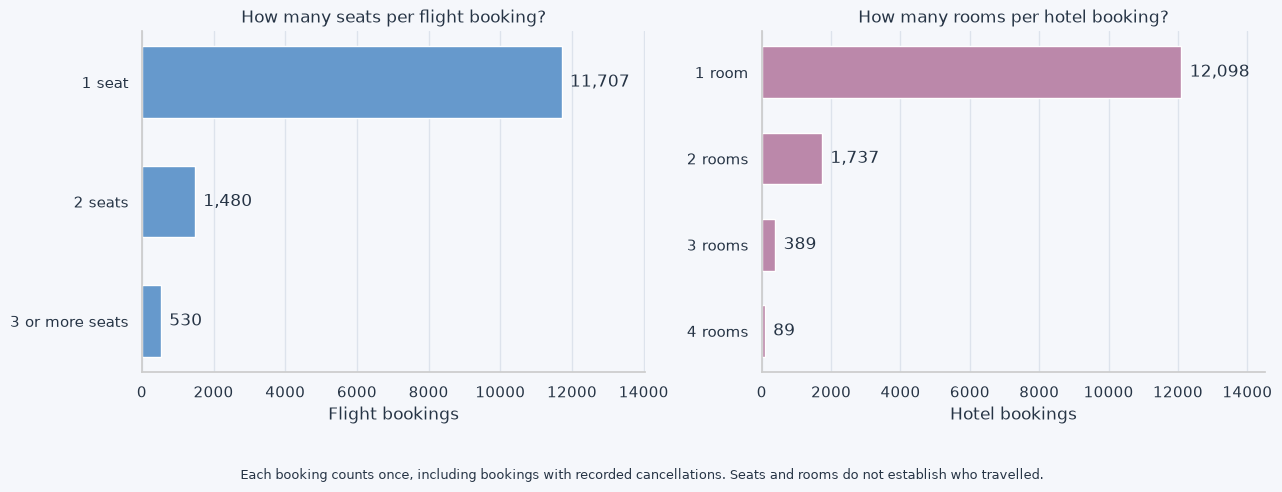

In [25]:
# group flight bookings by number of seats
# flugbuchungen nach sitzplatzanzahl gruppieren
seat_groups = pd.cut(
    flight_bookings["seats"],
    bins=[0, 1, 2, np.inf],
    labels=[
        "1 seat",
        "2 seats",
        "3 or more seats",
    ],
)

seat_counts = (
    seat_groups
    .value_counts()
    .reindex(
        ["1 seat", "2 seats", "3 or more seats"],
        fill_value=0,
    )
)

# count hotel bookings by number of rooms
# hotelbuchungen nach zimmeranzahl zählen
room_counts = (
    hotel_bookings["rooms"]
    .value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
)

room_counts.index = [
    "1 room",
    "2 rooms",
    "3 rooms",
    "4 rooms",
]

if (
    seat_counts.sum() != len(flight_bookings)
    or room_counts.sum() != len(hotel_bookings)
):
    raise ValueError("Not all bookings were counted.")

# show booking sizes using straightforward categories
# buchungsgrößen mit verständlichen kategorien zeigen
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

chart_settings = [
    (
        axes[0],
        seat_counts,
        COLORS["blue"],
        "How many seats per flight booking?",
        "Flight bookings",
    ),
    (
        axes[1],
        room_counts,
        COLORS["lavender"],
        "How many rooms per hotel booking?",
        "Hotel bookings",
    ),
]

for ax, counts, color, title, xlabel in chart_settings:
    bars = ax.barh(
        counts.index,
        counts.to_numpy(dtype=int),
        color=color,
        height=0.6,
    )

    ax.bar_label(
        bars,
        labels=[f"{int(count):,}" for count in counts],
        padding=6,
        color=COLORS["text"],
    )

    ax.set(
        title=title,
        xlabel=xlabel,
        ylabel="",
        xlim=(0, counts.max() * 1.2),
    )

    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.1, 1, 1))

fig.text(
    0.5,
    0.025,
    "Each booking counts once, including bookings with recorded cancellations. "
    "Seats and rooms do not establish who travelled.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

## 2.16 Flight distances per user
## 2.16 Flugentfernungen je Nutzer

Calculate each user's average one-way flight distance and count
flight bookings in each distance group:

- Short: less than 1,500 km
- Medium: 1,500 to less than 4,000 km
- Long: 4,000 km or more

Each flight booking counts once, including bookings with recorded
cancellations. Distances describe the great-circle distance between
airports, not the actual flight path.

Users without flight bookings receive zero booking counts and
a missing average distance.

Je Nutzer die durchschnittliche einfache Flugdistanz sowie die
Anzahl der Flugbuchungen je Distanzgruppe berechnen:

- Short: unter 1.500 km
- Medium: 1.500 bis unter 4.000 km
- Long: ab 4.000 km

Jede Flugbuchung zählt einmal, einschließlich Buchungen mit
verzeichneter Stornierung. Die Entfernung beschreibt die Luftlinie
zwischen Flughäfen, nicht die tatsächlich geflogene Strecke.

Nutzer ohne Flugbuchungen erhalten Buchungsanzahlen von null
und eine fehlende durchschnittliche Entfernung.

In [26]:
# calculate average one-way flight distance per user
# durchschnittliche einfache flugdistanz je nutzer berechnen
user_distance_average = (
    flight_bookings
    .groupby("user_id")["flight_distance_km"]
    .mean()
    .rename("avg_flight_distance_km")
    .reset_index()
)

# count flight bookings by distance group per user
# flugbuchungen je distanzgruppe und nutzer zählen
distance_count_names = {
    "Short": "short_flight_count",
    "Medium": "medium_flight_count",
    "Long": "long_flight_count",
}

user_distance_counts = (
    pd.crosstab(
        flight_bookings["user_id"],
        flight_bookings["flight_distance_group"],
    )
    .reindex(
        columns=list(distance_count_names),
        fill_value=0,
    )
    .rename(columns=distance_count_names)
    .reset_index()
)

count_columns = list(distance_count_names.values())
distance_columns = ["avg_flight_distance_km"] + count_columns

user_features = (
    user_features
    .drop(columns=distance_columns, errors="ignore")
    .merge(
        user_distance_average,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        user_distance_counts,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

for column in count_columns:
    user_features[column] = (
        user_features[column].fillna(0).astype("Int64")
    )

# each flight must appear in exactly one distance group
# jeder flug muss genau einer distanzgruppe zugeordnet sein
has_flights = user_features["flight_trip_count"].gt(0)
known_distances = user_features[
    "avg_flight_distance_km"
].dropna()

if (
    len(user_features) != len(users_clean)
    or not user_features[count_columns].sum(axis=1).eq(
        user_features["flight_trip_count"]
    ).all()
    or not user_features["avg_flight_distance_km"]
        .notna().eq(has_flights).all()
    or not np.isfinite(
        known_distances.to_numpy(dtype=float)
    ).all()
    or known_distances.le(0).any()
):
    raise ValueError("Check the user-level flight distances.")

display(style_overview(
    user_features[[
        "user_id",
        "flight_trip_count",
        "avg_flight_distance_km",
        "short_flight_count",
        "medium_flight_count",
        "long_flight_count",
    ]].head(10),
    "Users — Flight distances and booking counts",
    {
        "user_id": "{:.0f}",
        "flight_trip_count": "{:,.0f}",
        "avg_flight_distance_km": "{:,.1f}",
        "short_flight_count": "{:,.0f}",
        "medium_flight_count": "{:,.0f}",
        "long_flight_count": "{:,.0f}",
    },
))

print("User-level flight distance metrics passed.")

user_id,flight_trip_count,avg_flight_distance_km,short_flight_count,medium_flight_count,long_flight_count
23557,0,—,0,0,0
94883,2,"1,448.1",1,1,0
101486,1,965.3,1,0,0
101961,5,"1,321.0",4,0,1
106907,1,"13,408.5",0,0,1
118043,3,"2,448.0",1,2,0
120851,1,"2,238.9",0,1,0
125845,3,"2,698.9",0,3,0
133058,1,"2,708.3",0,1,0
149058,5,"1,911.4",3,2,0


User-level flight distance metrics passed.


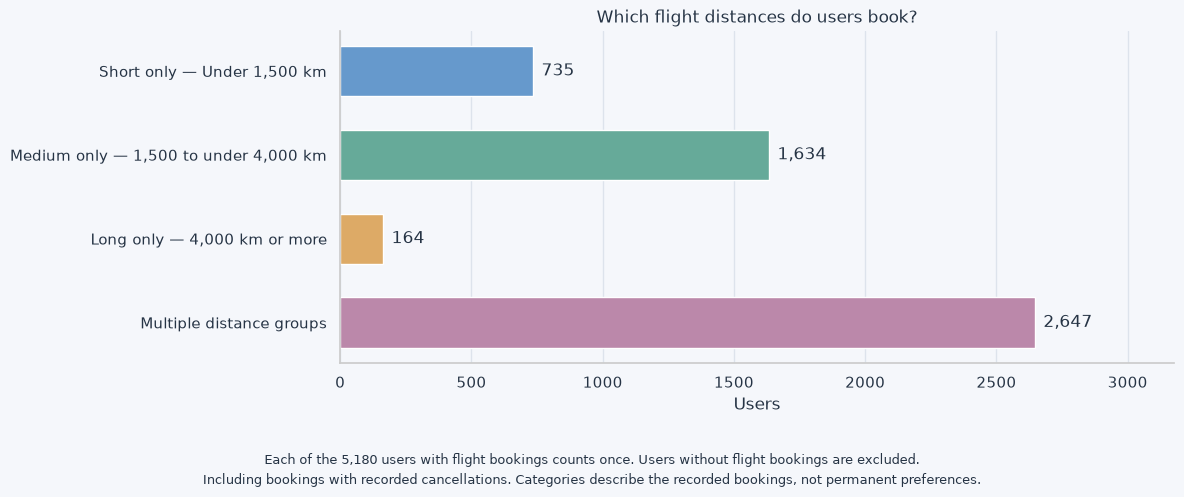

In [27]:
# classify the distance mix of each user's flight bookings
# distanzmix der flugbuchungen je nutzer einordnen
distance_users = user_features.loc[
    user_features["flight_trip_count"].gt(0)
].copy()

distance_users["distance_pattern"] = np.select(
    [
        distance_users["short_flight_count"].eq(
            distance_users["flight_trip_count"]
        ),
        distance_users["medium_flight_count"].eq(
            distance_users["flight_trip_count"]
        ),
        distance_users["long_flight_count"].eq(
            distance_users["flight_trip_count"]
        ),
    ],
    [
        "Short only — Under 1,500 km",
        "Medium only — 1,500 to under 4,000 km",
        "Long only — 4,000 km or more",
    ],
    default="Multiple distance groups",
)

distance_pattern_order = [
    "Short only — Under 1,500 km",
    "Medium only — 1,500 to under 4,000 km",
    "Long only — 4,000 km or more",
    "Multiple distance groups",
]

distance_user_counts = (
    distance_users["distance_pattern"]
    .value_counts()
    .reindex(distance_pattern_order, fill_value=0)
)

if distance_user_counts.sum() != len(distance_users):
    raise ValueError("Not all users were counted.")

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.barh(
    distance_user_counts.index,
    distance_user_counts.to_numpy(dtype=int),
    color=[
        COLORS["blue"],
        COLORS["mint"],
        COLORS["orange"],
        COLORS["lavender"],
    ],
    height=0.6,
)

ax.bar_label(
    bars,
    labels=[
        f"{int(count):,}"
        for count in distance_user_counts
    ],
    padding=6,
    color=COLORS["text"],
)

ax.set(
    title="Which flight distances do users book?",
    xlabel="Users",
    ylabel="",
    xlim=(0, distance_user_counts.max() * 1.2),
)

ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.12, 1, 1))

fig.text(
    0.5,
    0.055,
    f"Each of the {len(distance_users):,} users with flight bookings "
    "counts once. Users without flight bookings are excluded.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.015,
    "Including bookings with recorded cancellations. "
    "Categories describe the recorded bookings, not permanent preferences.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

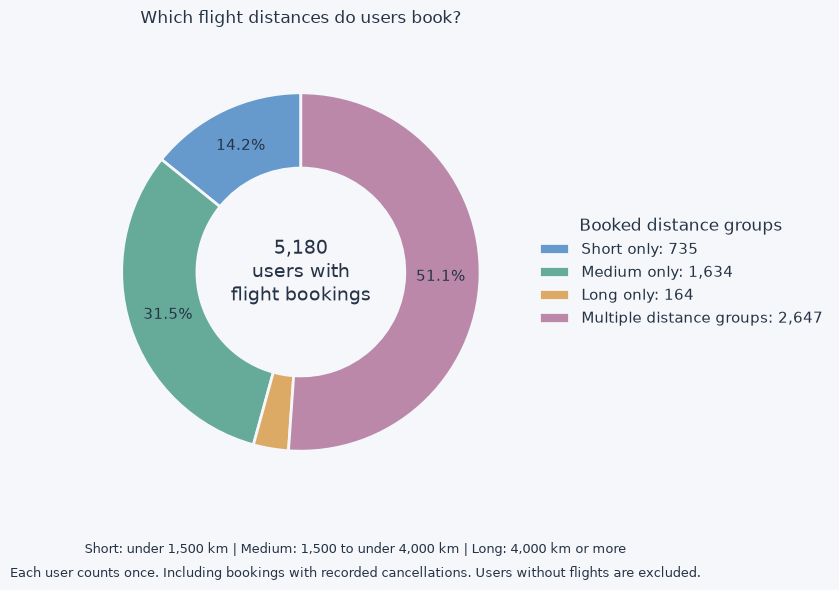

In [28]:
# show the composition of users by booked distance groups
# zusammensetzung der nutzer nach gebuchten distanzgruppen zeigen
fig, ax = plt.subplots(figsize=(11, 6))

short_labels = [
    "Short only",
    "Medium only",
    "Long only",
    "Multiple distance groups",
]

wedges, _, _ = ax.pie(
    distance_user_counts.to_numpy(dtype=int),
    colors=[
        COLORS["blue"],
        COLORS["mint"],
        COLORS["orange"],
        COLORS["lavender"],
    ],
    startangle=90,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
    pctdistance=0.78,
    textprops={
        "color": COLORS["text"],
        "fontsize": 11,
    },
    wedgeprops={
        "width": 0.42,
        "edgecolor": COLORS["background"],
        "linewidth": 2,
    },
)

ax.text(
    0,
    0,
    f"{len(distance_users):,}\nusers with\nflight bookings",
    ha="center",
    va="center",
    fontsize=14,
    color=COLORS["text"],
)

ax.legend(
    wedges,
    [
        f"{label}: {int(count):,}"
        for label, count in zip(
            short_labels,
            distance_user_counts,
        )
    ],
    title="Booked distance groups",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
)

ax.set_title(
    "Which flight distances do users book?",
    pad=18,
)

fig.tight_layout(rect=(0, 0.13, 1, 1))

fig.text(
    0.5,
    0.065,
    "Short: under 1,500 km | Medium: 1,500 to under 4,000 km | "
    "Long: 4,000 km or more",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.025,
    "Each user counts once. Including bookings with recorded cancellations. "
    "Users without flights are excluded.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

## 2.17 Review the existing user features
## 2.17 Vorhandene Nutzermerkmale sichten

List the calculated features added to the original user information.
Check missing values and the number of different values before
selecting features for clustering.

Not every calculated column will become a model input.
Some columns provide denominators, context or data-quality information.

Die berechneten Merkmale auflisten, die zu den ursprünglichen
Nutzerinformationen hinzugekommen sind. Fehlende Werte und die
Anzahl unterschiedlicher Werte vor der Merkmalsauswahl prüfen.

Nicht jede berechnete Spalte wird eine Modelleingabe.
Einige Spalten liefern Bezugsgrößen, Kontext oder Informationen
zur Datenqualität.

In [29]:
# identify columns added during feature engineering
# während der merkmalsentwicklung ergänzte spalten bestimmen
feature_columns = [
    column
    for column in user_features.columns
    if column not in users_clean.columns
]

feature_overview = pd.DataFrame([
    {
        "feature": column,
        "users_with_known_value": int(
            user_features[column].notna().sum()
        ),
        "users_with_missing_value": int(
            user_features[column].isna().sum()
        ),
        "different_known_values": int(
            user_features[column].nunique()
        ),
    }
    for column in feature_columns
])

feature_overview_display = feature_overview.rename(columns={
    "feature": "Feature",
    "users_with_known_value": "Users with a value",
    "users_with_missing_value": "Users without a value",
    "different_known_values": "Distinct values",
})

display(style_overview(
    feature_overview_display,
    "User features — Current inventory",
    {
        "Users with a value": "{:,.0f}",
        "Users without a value": "{:,.0f}",
        "Distinct values": "{:,.0f}",
    },
))

print("Users:", len(user_features))
print("Calculated feature columns:", len(feature_columns))

Feature,Users with a value,Users without a value,Distinct values
session_count,"5,998",0,5
avg_session_duration_minutes_non_cancel,"5,998",0,"2,622"
non_cancellation_session_count,"5,998",0,7
booking_session_count,"5,998",0,9
booking_session_share_pct,"5,998",0,33
trip_count,"5,998",0,9
cancelled_trip_count,"5,998",0,3
cancelled_trip_share_pct,"5,542",456,10
flight_only_trip_share_pct,"5,542",456,14
hotel_only_trip_share_pct,"5,542",456,14


Users: 5998
Calculated feature columns: 29


## 2.18 Days between booking and departure or check-in
## 2.18 Tage zwischen Buchung und Abflug oder Check-in

Calculate the calendar-day difference between the original booking
session and departure or hotel check-in. Then calculate the average
for each user, separately for flights and hotels.

A same-day booking has a lead time of zero days.
If the original booking session is outside the filtered data,
the lead time remains unknown.

Bookings with recorded cancellations remain included.
Lead time describes booking behaviour, not the reason for travelling.

Die Kalendertage zwischen der ursprünglichen Buchungssession und
dem Abflug beziehungsweise Hotel-Check-in berechnen. Anschließend
den Durchschnitt je Nutzer für Flüge und Hotels getrennt bilden.

Eine Buchung am selben Tag hat einen Vorlauf von null Tagen.
Liegt die ursprüngliche Buchungssession außerhalb der gefilterten
Daten, bleibt der Vorlauf unbekannt.

Buchungen mit verzeichneter Stornierung bleiben berücksichtigt.
Der Vorlauf beschreibt Buchungsverhalten, nicht den Reisegrund.

In [30]:
# identify the original booking date for each trip
# ursprüngliches buchungsdatum je reise bestimmen
if original_booking_sessions["trip_id"].duplicated().any():
    raise ValueError("Multiple booking sessions found for one trip.")

booking_dates = original_booking_sessions.set_index(
    "trip_id"
)["session_start"]

lead_time_rows = []

booking_settings = [
    (
        "Flight",
        flight_bookings,
        "departure_time",
        "avg_flight_booking_lead_days",
    ),
    (
        "Hotel",
        hotel_bookings,
        "check_in_time",
        "avg_hotel_booking_lead_days",
    ),
]

for label, bookings, start_column, feature_column in booking_settings:
    booking_check = bookings[[
        "trip_id",
        "user_id",
        start_column,
    ]].copy()

    booking_check["booking_time"] = (
        booking_check["trip_id"].map(booking_dates)
    )

    # compare calendar dates rather than full 24-hour periods
    # kalendertage statt vollständiger 24-stunden-blöcke vergleichen
    booking_check["lead_days"] = (
        booking_check[start_column].dt.normalize()
        - booking_check["booking_time"].dt.normalize()
    ).dt.days

    if booking_check["lead_days"].lt(0).any():
        raise ValueError(
            f"{label}: Some bookings occur after the recorded start date."
        )

    # missing booking dates remain excluded from the average
    # fehlende buchungsdaten bleiben vom durchschnitt ausgeschlossen
    user_lead_times = (
        booking_check
        .groupby("user_id")["lead_days"]
        .mean()
        .rename(feature_column)
        .reset_index()
    )

    user_features = (
        user_features
        .drop(columns=[feature_column], errors="ignore")
        .merge(
            user_lead_times,
            on="user_id",
            how="left",
            validate="one_to_one",
        )
    )

    if len(user_features) != len(users_clean):
        raise ValueError("The user count changed.")

    known_days = booking_check["lead_days"].dropna()

    lead_time_rows.append({
        "Booking type": label,
        "Bookings": len(booking_check),
        "Booking date missing": int(
            booking_check["booking_time"].isna().sum()
        ),
        "Users with a known average": int(
            user_features[feature_column].notna().sum()
        ),
        "Shortest notice (days)": known_days.min(),
        "Median notice (days)": known_days.median(),
        "Longest notice (days)": known_days.max(),
    })

lead_time_overview = pd.DataFrame(lead_time_rows)

display(style_overview(
    lead_time_overview,
    "How far in advance are bookings made?",
    {
        "Bookings": "{:,.0f}",
        "Booking date missing": "{:,.0f}",
        "Users with a known average": "{:,.0f}",
        "Shortest notice (days)": "{:,.0f}",
        "Median notice (days)": "{:,.0f}",
        "Longest notice (days)": "{:,.0f}",
    },
))

print("User-level booking lead times passed.")

Booking type,Bookings,Booking date missing,Users with a known average,Shortest notice (days),Median notice (days),Longest notice (days)
Flight,"13,717",7,"5,178",2,8,365
Hotel,"14,313",4,"5,401",0,8,366


User-level booking lead times passed.


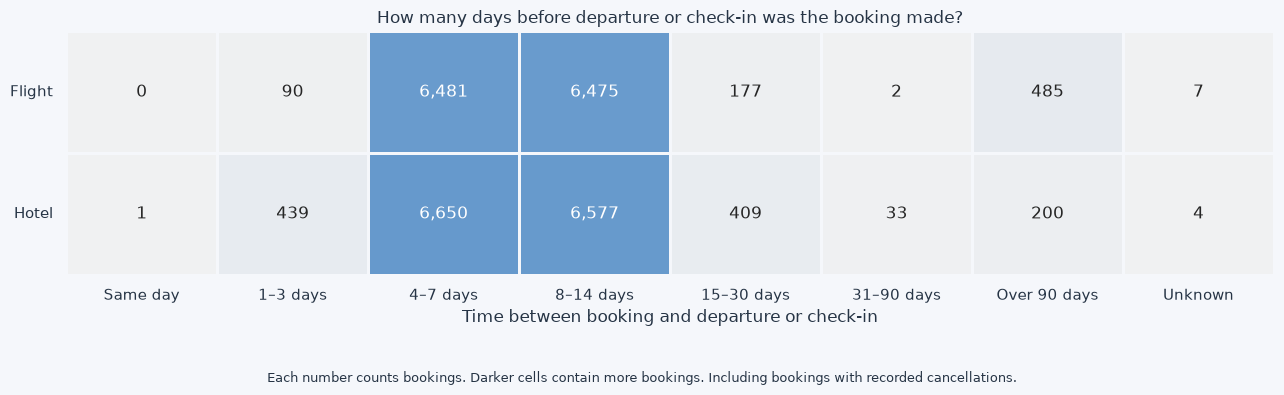

In [31]:
# group booking lead times for a clear visual comparison
# buchungsvorlauf für einen übersichtlichen vergleich gruppieren
notice_groups = [
    "Same day",
    "1–3 days",
    "4–7 days",
    "8–14 days",
    "15–30 days",
    "31–90 days",
    "Over 90 days",
    "Unknown",
]

notice_counts = {}

for label, bookings, start_column, _ in booking_settings:
    original_booking_time = bookings["trip_id"].map(
        booking_dates
    )

    lead_days = (
        bookings[start_column].dt.normalize()
        - original_booking_time.dt.normalize()
    ).dt.days

    groups = (
        pd.cut(
            lead_days,
            bins=[-0.5, 0.5, 3.5, 7.5, 14.5, 30.5, 90.5, np.inf],
            labels=notice_groups[:-1],
        )
        .astype("string")
        .fillna("Unknown")
    )

    counts = (
        groups.value_counts()
        .reindex(notice_groups, fill_value=0)
    )

    if counts.sum() != len(bookings):
        raise ValueError("Not all bookings were counted.")

    notice_counts[label] = counts

notice_table = (
    pd.DataFrame(notice_counts)
    .T
    .astype("int64")
)

fig, ax = plt.subplots(figsize=(13, 4))

sns.heatmap(
    notice_table,
    annot=True,
    fmt=",d",
    cmap=sns.light_palette(
        COLORS["blue"],
        as_cmap=True,
    ),
    linewidths=2,
    linecolor=COLORS["background"],
    cbar=False,
    ax=ax,
)

ax.set(
    title="How many days before departure or check-in was the booking made?",
    xlabel="Time between booking and departure or check-in",
    ylabel="",
)

ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.tight_layout(rect=(0, 0.12, 1, 1))

fig.text(
    0.5,
    0.025,
    "Each number counts bookings. Darker cells contain more bookings. "
    "Including bookings with recorded cancellations.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

## 2.19 Average trip duration per user
## 2.19 Durchschnittliche Reisedauer je Nutzer

Calculate the average known number of calendar days between
departure and return for each user, using the cleaned travel_days
column.

Bookings without a return flight and bookings with identical
departure and return timestamps have unknown durations.
They are excluded from the average and counted separately.

Bookings with recorded cancellations remain included.
The interval describes booked dates, not confirmed holidays
or completed travel.

Je Nutzer die durchschnittliche bekannte Anzahl der Kalendertage
zwischen Hin- und Rückflug berechnen. Grundlage ist die bereinigte
Spalte travel_days.

Buchungen ohne Rückflug sowie Buchungen mit identischen Hin- und
Rückflugzeitpunkten haben eine unbekannte Dauer. Sie werden beim
Durchschnitt ausgeschlossen und separat gezählt.

Buchungen mit verzeichneter Stornierung bleiben berücksichtigt.
Der Zeitraum beschreibt gebuchte Termine, keine bestätigten
Urlaubsreisen oder tatsächlich durchgeführten Reisen.

In [32]:
# identify bookings with unknown trip duration
# buchungen mit unbekannter reisedauer erkennen
flight_bookings["unknown_travel_days"] = (
    flight_bookings["travel_days"].isna()
)

# calculate average known duration per user
# durchschnittliche bekannte dauer je nutzer berechnen
user_travel_duration = (
    flight_bookings
    .groupby("user_id")
    .agg(
        avg_travel_days=("travel_days", "mean"),
        flights_with_unknown_travel_days=(
            "unknown_travel_days", "sum"
        ),
    )
    .reset_index()
)

duration_columns = [
    "avg_travel_days",
    "flights_with_unknown_travel_days",
]

user_features = (
    user_features
    .drop(columns=duration_columns, errors="ignore")
    .merge(
        user_travel_duration,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

# no flight bookings means zero affected bookings, not zero duration
# keine flugbuchungen bedeuten anzahl null, nicht reisedauer null
user_features["flights_with_unknown_travel_days"] = (
    user_features["flights_with_unknown_travel_days"]
    .fillna(0)
    .astype("Int64")
)

has_known_duration = (
    user_features["flight_trip_count"]
    > user_features["flights_with_unknown_travel_days"]
)

if (
    len(user_features) != len(users_clean)
    or not user_features["avg_travel_days"]
        .notna().eq(has_known_duration).all()
    or user_features["flights_with_unknown_travel_days"].sum()
        != flight_bookings["travel_days"].isna().sum()
    or user_features["avg_travel_days"].dropna().lt(0).any()
):
    raise ValueError("Check the user-level trip durations.")

known_trip_days = flight_bookings["travel_days"].dropna()

travel_duration_overview = pd.DataFrame({
    "Metric": [
        "Flight bookings",
        "Bookings with known duration",
        "Bookings with unknown duration",
        "Users with a known average duration",
        "Shortest booked interval (days)",
        "Median booked interval (days)",
        "Longest booked interval (days)",
    ],
    "Value": [
        f"{len(flight_bookings):,}",
        f"{len(known_trip_days):,}",
        f"{int(flight_bookings['travel_days'].isna().sum()):,}",
        f"{int(has_known_duration.sum()):,}",
        f"{known_trip_days.min():,.0f}",
        f"{known_trip_days.median():,.1f}",
        f"{known_trip_days.max():,.0f}",
    ],
})

display(style_overview(
    travel_duration_overview,
    "How many days are between departure and return?",
))

print("User-level trip durations passed.")

Metric,Value
Flight bookings,"13,717"
Bookings with known duration,"13,050"
Bookings with unknown duration,667
Users with a known average duration,"5,114"
Shortest booked interval (days),1
Median booked interval (days),3.0
Longest booked interval (days),35


User-level trip durations passed.


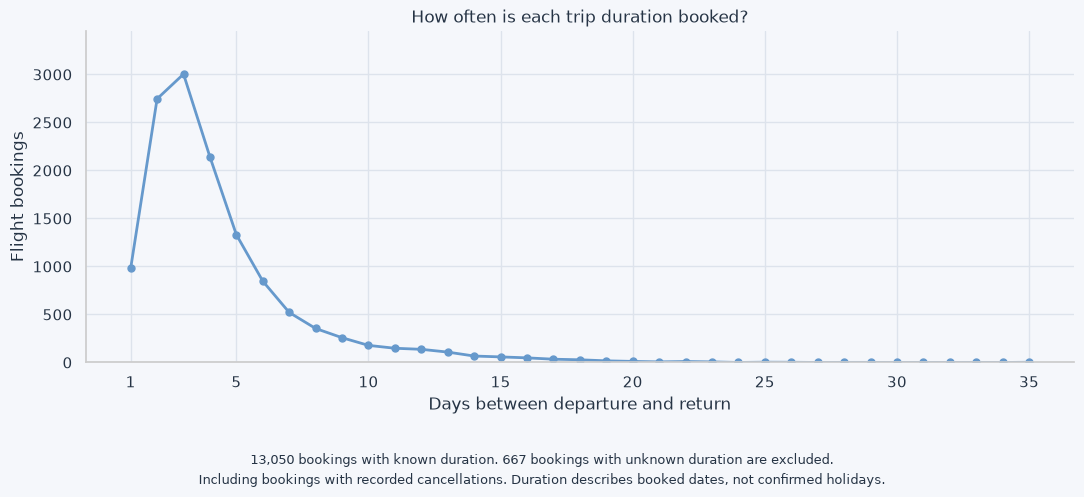

In [33]:
# count flight bookings for each known duration
# flugbuchungen je bekannter reisedauer zählen
duration_counts = (
    flight_bookings["travel_days"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

# include days with no bookings
# auch dauern ohne buchungen anzeigen
duration_counts = duration_counts.reindex(
    range(
        int(duration_counts.index.min()),
        int(duration_counts.index.max()) + 1,
    ),
    fill_value=0,
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    duration_counts.index,
    duration_counts.to_numpy(dtype=int),
    color=COLORS["blue"],
    linewidth=2,
    marker="o",
    markersize=5,
)

ax.set(
    title="How often is each trip duration booked?",
    xlabel="Days between departure and return",
    ylabel="Flight bookings",
    ylim=(0, duration_counts.max() * 1.15),
)

ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35])
ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.12, 1, 1))

fig.text(
    0.5,
    0.055,
    "13,050 bookings with known duration. "
    "667 bookings with unknown duration are excluded.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.015,
    "Including bookings with recorded cancellations. "
    "Duration describes booked dates, not confirmed holidays.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

### Result
### Ergebnis

The interval between departure and return is known for 13,050
flight bookings and ranges from 1 to 35 days, with a median of 3 days.

The 667 unknown durations comprise 597 bookings without a return
flight and 70 bookings with identical departure and return timestamps.
They are excluded from duration averages and the chart.

An average known duration could be calculated for 5,114 users.
The chart describes individual bookings, not user averages.

Der Zeitraum zwischen Hin- und Rückflug ist für 13.050 Flugbuchungen
bekannt. Er reicht von 1 bis 35 Tagen; der Median beträgt 3 Tage.

Die 667 unbekannten Zeiträume bestehen aus 597 Buchungen ohne
Rückflug und 70 Buchungen mit identischen Hin- und Rückflugzeitpunkten.
Sie werden aus den Durchschnittsberechnungen und der Grafik ausgeschlossen.

Für 5.114 Nutzer konnte eine durchschnittliche bekannte Dauer
berechnet werden. Die Grafik beschreibt einzelne Buchungen,
keine Nutzerdurchschnitte.

## 2.20 Estimated booking value per user
## 2.20 Geschätzter Buchungswert je Nutzer

Estimate the recorded booking value before discounts:

- Flight: the recorded base fare, counted once.
- Hotel: nightly room price × rooms × known positive nights.
- Combined trip: flight value plus estimated hotel value.

Unknown hotel nights and zero-night stays do not provide a reliable
hotel total. The complete trip value remains missing in these cases,
rather than showing only the flight component.

Calculate the average known trip value per user.
Bookings with recorded cancellations remain included.
These values are estimates, not confirmed payments or revenue.

Den erfassten Buchungswert vor Rabatten schätzen:

- Flug: den verzeichneten Grundpreis einmal berücksichtigen.
- Hotel: Zimmerpreis pro Nacht × Zimmer × bekannte positive Nächte.
- Kombinierte Reise: Flugwert plus geschätzter Hotelwert.

Bei reinen Flugbuchungen entspricht der Buchungswert dem Flugpreis.

Wurde zusätzlich ein Hotel gebucht, dessen Gesamtwert wegen
ungeklärter oder null Nächte nicht berechenbar ist, bleibt der
vollständige Buchungswert unbekannt. Der Flugpreis bleibt als
einzelner Bestandteil erhalten.

In [34]:
# bring booking values together once per trip
# buchungswerte einmal je reise zusammenführen
trip_values = (
    trips[[
        "trip_id",
        "user_id",
        "booking_type",
        "has_flight_record",
        "has_hotel_record",
    ]]
    .merge(
        flights_clean[["trip_id", "base_fare_usd"]],
        on="trip_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        hotels_clean[[
            "trip_id",
            "hotel_per_room_usd",
            "rooms",
            "nights",
        ]],
        on="trip_id",
        how="left",
        validate="one_to_one",
    )
)

# estimate hotel totals only for known positive night counts
# hotelgesamtwerte nur bei bekannten positiven nächtezahlen schätzen
trip_values["estimated_hotel_value_usd"] = (
    trip_values["hotel_per_room_usd"]
    * trip_values["rooms"]
    * trip_values["nights"]
).where(trip_values["nights"].gt(0))

# absent components contribute zero; unknown components stay missing
# nicht gebuchte bestandteile zählen null; unbekannte bleiben fehlend
flight_component = trip_values["base_fare_usd"].where(
    trip_values["has_flight_record"],
    0,
)

hotel_component = trip_values["estimated_hotel_value_usd"].where(
    trip_values["has_hotel_record"],
    0,
)

trip_values["estimated_trip_value_usd"] = (
    flight_component + hotel_component
)

trip_values["value_unknown"] = (
    trip_values["estimated_trip_value_usd"].isna()
)

# calculate the average known trip value per user
# durchschnittlichen bekannten reisewert je nutzer berechnen
user_value_metrics = (
    trip_values
    .groupby("user_id")
    .agg(
        avg_trip_booking_value_usd=(
            "estimated_trip_value_usd", "mean"
        ),
        trips_with_unknown_booking_value=(
            "value_unknown", "sum"
        ),
    )
    .reset_index()
)

value_columns = [
    "avg_trip_booking_value_usd",
    "trips_with_unknown_booking_value",
]

user_features = (
    user_features
    .drop(columns=value_columns, errors="ignore")
    .merge(
        user_value_metrics,
        on="user_id",
        how="left",
        validate="one_to_one",
    )
)

user_features["trips_with_unknown_booking_value"] = (
    user_features["trips_with_unknown_booking_value"]
    .fillna(0)
    .astype("Int64")
)

has_known_value = (
    user_features["trip_count"]
    > user_features["trips_with_unknown_booking_value"]
)

known_values = trip_values[
    "estimated_trip_value_usd"
].dropna()

if (
    len(trip_values) != len(trips)
    or len(user_features) != len(users_clean)
    or not user_features["avg_trip_booking_value_usd"]
        .notna().eq(has_known_value).all()
    or not np.isfinite(
        known_values.to_numpy(dtype=float)
    ).all()
    or known_values.le(0).any()
    or user_features["trips_with_unknown_booking_value"].sum()
        != trip_values["value_unknown"].sum()
):
    raise ValueError("Check the estimated booking values.")

# compare known values across booking types
# bekannte werte zwischen den buchungsarten vergleichen
value_overview = (
    trip_values
    .groupby("booking_type")
    .agg(
        Trips=("trip_id", "size"),
        Known_values=("estimated_trip_value_usd", "count"),
        Unknown_values=("value_unknown", "sum"),
        Median_value_USD=("estimated_trip_value_usd", "median"),
        Average_value_USD=("estimated_trip_value_usd", "mean"),
    )
    .reset_index()
    .rename(columns={
        "booking_type": "Booking type",
        "Known_values": "Known values",
        "Unknown_values": "Unknown values",
        "Median_value_USD": "Median value (USD)",
        "Average_value_USD": "Average value (USD)",
    })
)

display(style_overview(
    value_overview,
    "Estimated booking values before discounts",
    {
        "Trips": "{:,.0f}",
        "Known values": "{:,.0f}",
        "Unknown values": "{:,.0f}",
        "Median value (USD)": "${:,.2f}",
        "Average value (USD)": "${:,.2f}",
    },
))

print("User-level estimated booking values passed.")

Booking type,Trips,Known values,Unknown values,Median value (USD),Average value (USD)
Flight and hotel,"11,931","11,501",430,$901.79,"$1,220.63"
Flight only,"1,786","1,786",0,$426.54,$764.10
Hotel only,"2,382","2,382",0,"$1,130.50","$1,756.21"


User-level estimated booking values passed.


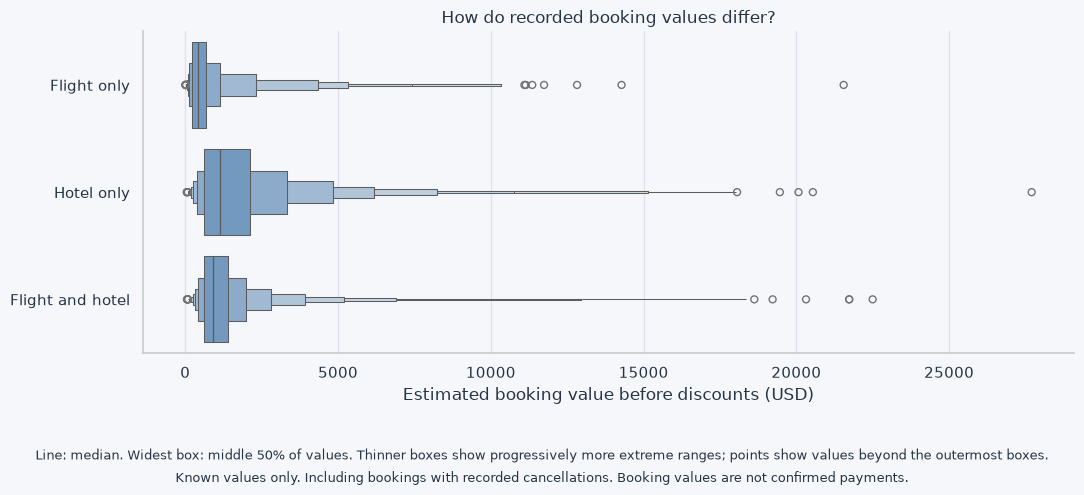

In [35]:
# compare known booking values across booking types
# bekannte buchungswerte zwischen buchungsarten vergleichen
value_plot_data = trip_values.loc[
    trip_values["estimated_trip_value_usd"].notna()
].copy()

booking_value_order = [
    "Flight only",
    "Hotel only",
    "Flight and hotel",
]

fig, ax = plt.subplots(figsize=(11, 5))

sns.boxenplot(
    data=value_plot_data,
    x="estimated_trip_value_usd",
    y="booking_type",
    order=booking_value_order,
    color=COLORS["blue"],
    showfliers=True,
    ax=ax,
)

ax.set(
    title="How do recorded booking values differ?",
    xlabel="Estimated booking value before discounts (USD)",
    ylabel="",
)

ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout(rect=(0, 0.14, 1, 1))

fig.text(
    0.5,
    0.065,
    "Line: median. Widest box: middle 50% of values. "
    "Thinner boxes show progressively more extreme ranges; "
    "points show values beyond the outermost boxes.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

fig.text(
    0.5,
    0.02,
    "Known values only. Including bookings with recorded cancellations. "
    "Booking values are not confirmed payments.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

### Result
### Ergebnis

Known estimated booking values differ across booking types:

- Flight only: median $426.54.
- Hotel only: median $1,130.50.
- Flight and hotel: median $901.79.

For each booking type, the mean exceeds the median. The boxenplot
shows extended tails towards higher values.

Complete values are unavailable for 430 combined bookings:
226 have unresolved hotel nights and 204 have zero calendar nights
without a known day-use price.

Differences between booking types may reflect room counts,
stay lengths, seats and other booking characteristics.
The estimates are before discounts and include bookings with
recorded cancellations. They are not confirmed payments.

Die bekannten geschätzten Buchungswerte unterscheiden sich
zwischen den Buchungsarten:

- Nur Flug: Median 426,54 USD.
- Nur Hotel: Median 1.130,50 USD.
- Flug und Hotel: Median 901,79 USD.

Bei jeder Buchungsart liegt der Mittelwert über dem Median.
Der Boxenplot zeigt längere Ausläufer in Richtung hoher Werte.

Für 430 kombinierte Buchungen fehlt ein vollständiger Wert:
226 haben ungeklärte Hotelnächte, 204 haben null Kalendernächte
ohne bekannten Tagespreis.

Unterschiede zwischen den Buchungsarten können unter anderem
durch Zimmeranzahl, Aufenthaltsdauer und Sitzplätze entstehen.
Die Schätzwerte gelten vor Rabatten und enthalten Buchungen mit
verzeichneter Stornierung. Sie sind keine bestätigten Zahlungen.

## 2.21 Review all calculated features
## 2.21 Alle berechneten Merkmale prüfen

Review the complete feature inventory before selecting model inputs.
Counts used for calculations and data-quality checks are not
automatically included in clustering.

Vor der Auswahl der Modelleingaben alle berechneten Merkmale sichten.
Anzahlwerte für Berechnungen und Datenqualitätsprüfungen werden
nicht automatisch für das Clustering verwendet.

In [36]:
# readable feature titles for tables, charts and reports
# verständliche merkmalsnamen für tabellen, grafiken und berichte
FEATURE_LABELS = {
    # sessions and bookings
    # sessions und buchungen
    "session_count":
        "Sessions per user",
    "avg_session_duration_minutes_non_cancel":
        "Average session duration (minutes)",
    "non_cancellation_session_count":
        "Sessions excluding cancellations",
    "booking_session_count":
        "Sessions with a booking",
    "booking_session_share_pct":
        "Sessions with a booking (%)",

    # trips and cancellations
    # reisen und stornierungen
    "trip_count":
        "Recorded trips",
    "cancelled_trip_count":
        "Trips with a recorded cancellation",
    "cancelled_trip_share_pct":
        "Trips with a recorded cancellation (%)",

    # booking types
    # buchungsarten
    "flight_only_trip_share_pct":
        "Flight-only trips (%)",
    "hotel_only_trip_share_pct":
        "Hotel-only trips (%)",
    "flight_hotel_trip_share_pct":
        "Trips with flight and hotel (%)",

    # discounts
    # rabatte
    "flight_booking_count_with_discount_data":
        "Flight bookings with known discount status",
    "flight_discount_booking_share_pct":
        "Flight bookings with a discount (%)",
    "hotel_booking_count_with_discount_data":
        "Hotel bookings with known discount status",
    "hotel_discount_booking_share_pct":
        "Hotel bookings with a discount (%)",
    "avg_flight_discount_pct":
        "Average discount on discounted flight bookings (%)",
    "avg_hotel_discount_pct":
        "Average discount on discounted hotel bookings (%)",

    # baggage
    # gepäck
    "flight_trip_count":
        "Flight bookings",
    "flight_with_baggage_count":
        "Flight bookings with checked baggage",
    "total_checked_bags":
        "Checked bags booked",

    # hotels
    # hotels
    "hotel_trip_count":
        "Hotel bookings",
    "hotel_trips_with_unknown_nights":
        "Hotel bookings with unknown nights",
    "avg_hotel_nights":
        "Average nights per hotel booking",

    # booking size
    # buchungsgröße
    "avg_seats_per_flight_booking":
        "Average seats per flight booking",
    "avg_rooms_per_hotel_booking":
        "Average rooms per hotel booking",

    # distance
    # entfernung
    "avg_flight_distance_km":
        "Average one-way flight distance (km)",
    "short_flight_count":
        "Short-distance flight bookings",
    "medium_flight_count":
        "Medium-distance flight bookings",
    "long_flight_count":
        "Long-distance flight bookings",

    # booking lead time
    # buchungsvorlauf
    "avg_flight_booking_lead_days":
        "Average days from booking to departure",
    "avg_hotel_booking_lead_days":
        "Average days from booking to check-in",

    # trip duration
    # reisedauer
    "avg_travel_days":
        "Average days between departure and return",
    "flights_with_unknown_travel_days":
        "Flight bookings with unknown trip duration",

    # booking values
    # buchungswerte
    "avg_trip_booking_value_usd":
        "Average estimated booking value (USD)",
    "trips_with_unknown_booking_value":
        "Trips with unknown booking value",
}

In [37]:
# identify all calculated feature columns
# alle berechneten merkmalsspalten bestimmen
feature_columns = [
    column
    for column in user_features.columns
    if column not in users_clean.columns
]

# ensure that every feature has a readable title
# sicherstellen, dass jedes merkmal einen verständlichen titel hat
missing_labels = [
    column
    for column in feature_columns
    if column not in FEATURE_LABELS
]

if missing_labels:
    raise ValueError(
        f"Add readable titles for these features: {missing_labels}"
    )

feature_overview = pd.DataFrame([
    {
        "Feature": FEATURE_LABELS[column],
        "Users with a value": int(
            user_features[column].notna().sum()
        ),
        "Users without a value": int(
            user_features[column].isna().sum()
        ),
        "Distinct values": int(
            user_features[column].nunique()
        ),
    }
    for column in feature_columns
])

display(style_overview(
    feature_overview,
    "User features — Complete inventory",
    {
        "Users with a value": "{:,.0f}",
        "Users without a value": "{:,.0f}",
        "Distinct values": "{:,.0f}",
    },
))

print("Users:", len(user_features))
print("Calculated columns:", len(feature_columns))

Feature,Users with a value,Users without a value,Distinct values
Sessions per user,"5,998",0,5
Average session duration (minutes),"5,998",0,"2,622"
Sessions excluding cancellations,"5,998",0,7
Sessions with a booking,"5,998",0,9
Sessions with a booking (%),"5,998",0,33
Recorded trips,"5,998",0,9
Trips with a recorded cancellation,"5,998",0,3
Trips with a recorded cancellation (%),"5,542",456,10
Flight-only trips (%),"5,542",456,14
Hotel-only trips (%),"5,542",456,14


Users: 5998
Calculated columns: 35


## 2.22 Check relationships between features
## 2.22 Zusammenhänge zwischen Merkmalen prüfen

Compare selected feature pairs to identify potentially overlapping
information. Calculate Pearson correlations using users with known
values for both features.

A strong correlation does not automatically make a feature unnecessary.
Its meaning and relevance to customer benefits must also be considered.

Ausgewählte Merkmalspaare vergleichen, um mögliche Überschneidungen
zu erkennen. Pearson-Korrelationen für Nutzer berechnen, bei denen
beide Werte bekannt sind.

Ein starker Zusammenhang macht ein Merkmal nicht automatisch
überflüssig. Seine Bedeutung und sein Bezug zu den Kundenvorteilen
werden ebenfalls berücksichtigt.

In [38]:
# examine selected pairs rather than all possible combinations
# ausgewählte paare statt aller möglichen kombinationen untersuchen
feature_pairs = [
    (
        "booking_session_count",
        "trip_count",
    ),
    (
        "flight_trip_count",
        "flight_booking_count_with_discount_data",
    ),
    (
        "hotel_trip_count",
        "hotel_booking_count_with_discount_data",
    ),
    (
        "session_count",
        "non_cancellation_session_count",
    ),
    (
        "avg_seats_per_flight_booking",
        "avg_rooms_per_hotel_booking",
    ),
    (
        "avg_hotel_nights",
        "avg_travel_days",
    ),
    (
        "avg_flight_booking_lead_days",
        "avg_hotel_booking_lead_days",
    ),
    (
        "flight_with_baggage_count",
        "total_checked_bags",
    ),
    (
        "avg_trip_booking_value_usd",
        "avg_hotel_nights",
    ),
    (
        "avg_trip_booking_value_usd",
        "avg_flight_distance_km",
    ),
]

relationship_rows = []

for first_feature, second_feature in feature_pairs:
    # compare only users with both values available
    # nur nutzer mit zwei bekannten werten vergleichen
    paired_values = (
        user_features[[first_feature, second_feature]]
        .dropna()
        .astype(float)
    )

    correlation = paired_values[first_feature].corr(
        paired_values[second_feature]
    )

    relationship_rows.append({
        "Feature A": FEATURE_LABELS[first_feature],
        "Feature B": FEATURE_LABELS[second_feature],
        "Users compared": len(paired_values),
        "Correlation": correlation,
    })

feature_relationships = pd.DataFrame(relationship_rows)

display(HTML(
    '<div style="overflow-x:auto;">'
    + style_overview(
        feature_relationships,
        "Selected features — Relationships",
        {
            "Users compared": "{:,.0f}",
            "Correlation": "{:.3f}",
        },
    ).to_html()
    + "</div>"
))

Feature A,Feature B,Users compared,Correlation
Sessions with a booking,Recorded trips,"5,998",1.000
Flight bookings,Flight bookings with known discount status,"5,998",1.000
Hotel bookings,Hotel bookings with known discount status,"5,998",1.000
Sessions per user,Sessions excluding cancellations,"5,998",0.822
Average seats per flight booking,Average rooms per hotel booking,"5,040",0.700
Average nights per hotel booking,Average days between departure and return,"4,967",0.638
Average days from booking to departure,Average days from booking to check-in,"5,039",0.688
Flight bookings with checked baggage,Checked bags booked,"5,998",0.921
Average estimated booking value (USD),Average nights per hotel booking,"5,373",0.535
Average estimated booking value (USD),Average one-way flight distance (km),"5,156",0.456


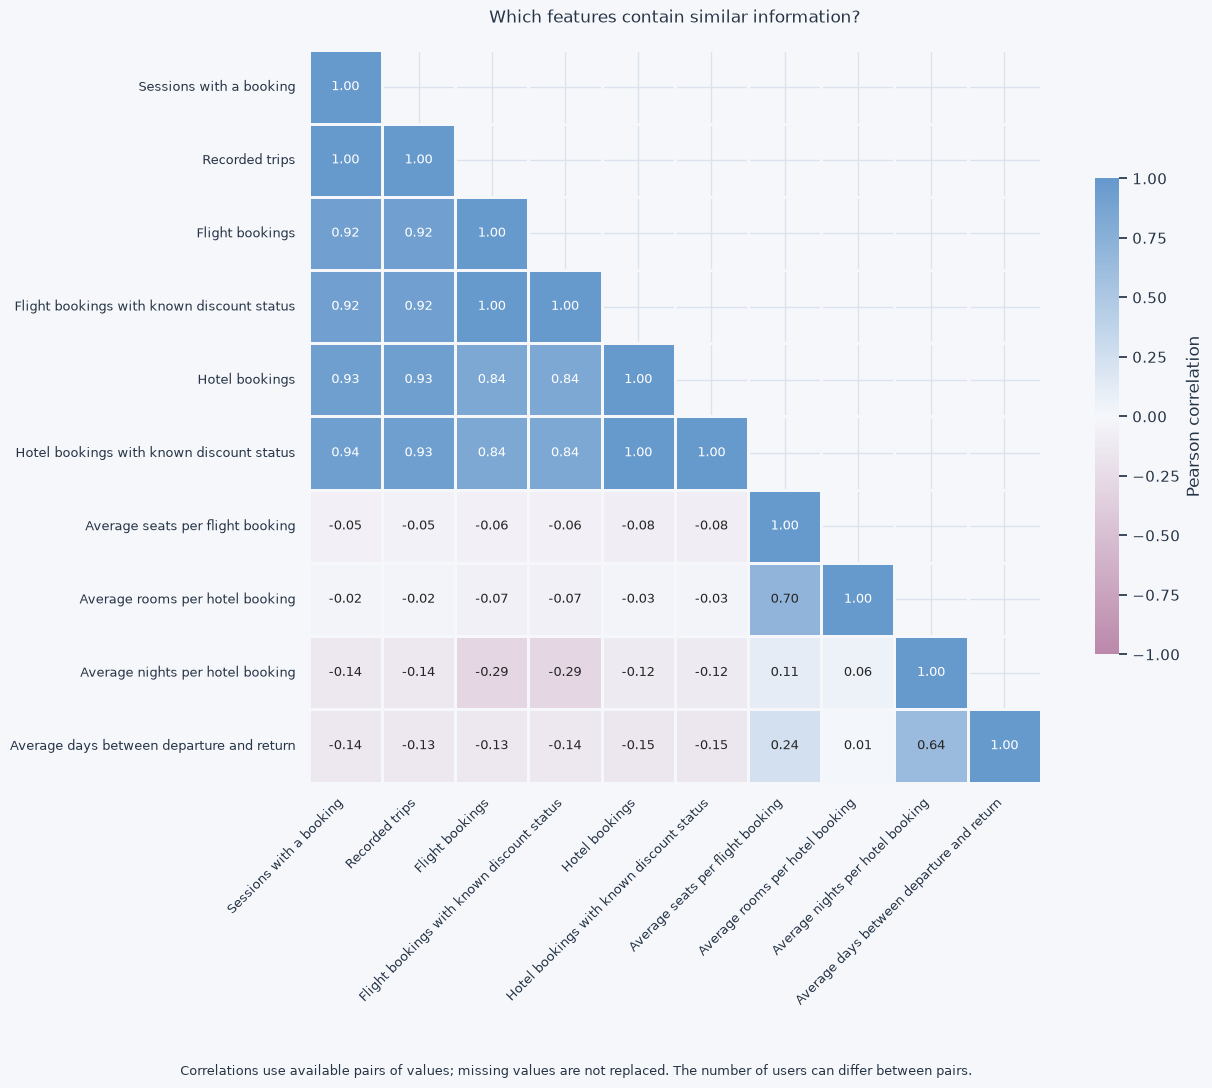

In [39]:
# select a readable subset for the correlation heatmap
# eine übersichtliche auswahl für die korrelations-heatmap verwenden
heatmap_features = [
    "booking_session_count",
    "trip_count",
    "flight_trip_count",
    "flight_booking_count_with_discount_data",
    "hotel_trip_count",
    "hotel_booking_count_with_discount_data",
    "avg_seats_per_flight_booking",
    "avg_rooms_per_hotel_booking",
    "avg_hotel_nights",
    "avg_travel_days",
]

# each correlation uses users with both values available
# jede korrelation verwendet nutzer mit zwei bekannten werten
correlation_matrix = (
    user_features[heatmap_features]
    .astype(float)
    .corr(method="pearson", min_periods=30)
)

# use the shared readable titles
# gemeinsame verständliche titel verwenden
correlation_matrix = correlation_matrix.rename(
    index=FEATURE_LABELS,
    columns=FEATURE_LABELS,
)

# hide the repeated upper half
# die doppelte obere hälfte ausblenden
upper_triangle = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1,
)

correlation_colors = sns.blend_palette(
    [
        COLORS["lavender"],
        COLORS["background"],
        COLORS["blue"],
    ],
    as_cmap=True,
)

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    mask=upper_triangle,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 9},
    cmap=correlation_colors,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    linecolor=COLORS["background"],
    cbar_kws={
        "label": "Pearson correlation",
        "shrink": 0.65,
    },
    ax=ax,
)

ax.set_title(
    "Which features contain similar information?",
    pad=20,
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=9,
)

plt.setp(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=9,
)

fig.tight_layout(rect=(0, 0.06, 1, 1))

fig.text(
    0.5,
    0.015,
    "Correlations use available pairs of values; missing values are not replaced. "
    "The number of users can differ between pairs.",
    ha="center",
    fontsize=9,
    color=COLORS["text"],
)

plt.show()

### What does Pearson correlation mean?
### Was bedeutet Pearson-Korrelation?

Pearson correlation measures how strongly two numerical features
follow a linear relationship. Values range from −1 to +1:

- Near +1: high values of one feature usually accompany high
  values of the other.
- Near −1: high values of one feature usually accompany low
  values of the other.
- Near 0: no strong linear relationship is visible.

Correlation does not prove causation. A value near zero does not
exclude curved relationships or other patterns.

Here, correlation helps identify features that may contain similar
information. It does not automatically decide which features to remove.

Die Pearson-Korrelation beschreibt, wie stark zwei Zahlenmerkmale
geradlinig zusammenhängen. Die Werte reichen von −1 bis +1:

- Nahe +1: Hohe Werte des einen Merkmals gehen meist mit hohen
  Werten des anderen einher.
- Nahe −1: Hohe Werte des einen Merkmals gehen meist mit niedrigen
  Werten des anderen einher.
- Nahe 0: Es ist kein starker geradliniger Zusammenhang erkennbar.

Ein Zusammenhang beweist keine Ursache. Ein Wert nahe null schließt
Kurven oder andere Muster nicht aus.

Hier hilft die Korrelation, Merkmale mit möglicherweise ähnlichen
Informationen zu erkennen. Sie entscheidet nicht automatisch,
welche Merkmale entfernt werden.

### Why were these features selected?
### Warum wurden diese Merkmale ausgewählt?

Features were selected based on their related meanings to investigate
potentially overlapping information.

The table examines selected pairs. The heatmap compares all ten
selected features with one another, producing 45 distinct pairs.

This is an initial, targeted check, not a complete examination of
all features or the final selection for clustering.

Die Merkmale wurden aufgrund ihrer inhaltlichen Nähe ausgewählt,
um mögliche Informationsüberschneidungen gezielt zu untersuchen.

Die Tabelle betrachtet ausgewählte Paarungen. Die Heatmap vergleicht
alle zehn ausgewählten Merkmale miteinander. Daraus entstehen
45 unterschiedliche Paarungen.

Dies ist eine erste gezielte Prüfung, keine vollständige Untersuchung
aller Merkmale und keine endgültige Auswahl für das Clustering.

### Result
### Ergebnis

Several booking-count features contain strongly overlapping information.
Correlations displayed as 1.000 are rounded and do not establish
identical values.

Recorded trip count is the preferred initial measure of booking
frequency. Counts of bookings with known discount status remain
calculation denominators rather than additional model inputs.

Baggage counts also overlap strongly. Booking size, duration and
lead-time features show related but distinct information and require
further consideration.

These findings guide a preliminary selection. No columns are removed
from the complete user table.

Mehrere Buchungsanzahlen enthalten stark überlappende Informationen.
Als 1,000 dargestellte Korrelationen sind gerundet und bedeuten
nicht, dass die Werte identisch sind.

Die Reiseanzahl ist zunächst das bevorzugte Merkmal für die
Buchungshäufigkeit. Anzahlen mit bekanntem Rabattstatus bleiben
Berechnungsgrundlagen statt zusätzlicher Modelleingaben.

Auch die Gepäckanzahlen überschneiden sich stark. Buchungsgröße,
Dauer und Buchungsvorlauf liefern verwandte, aber unterschiedliche
Informationen und werden weiter beurteilt.

Diese Ergebnisse unterstützen eine vorläufige Auswahl.
Aus der vollständigen Nutzertabelle werden keine Spalten entfernt.

### Rationale for the preliminary feature selection
### Begründung der vorläufigen Merkmalsauswahl

The 14 candidate features were selected using three considerations:

1. Relevance to the proposed customer benefits, particularly
   cancellation behaviour, discount usage and checked baggage.
2. Coverage of additional travel characteristics: booking lead time,
   duration, booking size, distance and estimated booking value.
3. Reduction of overlapping information identified in the previous
   checks, especially similar booking counts.

Two booking-type percentages are included: flight only and hotel only.
The combined flight-and-hotel percentage follows from these two
and does not need to be included separately.

Some exclusions remain open to review. Average room count may provide
information for hotel-only users, while session behaviour may help
describe users without bookings. Correlation alone does not determine
whether a feature is useful.

All calculated features remain in the complete user table.
The selection will be reviewed before clustering, considering
missing values, user coverage and business meaning.

Die 14 Merkmalskandidaten wurden anhand von drei Überlegungen ausgewählt:

1. Bezug zu den vorgeschlagenen Kundenvorteilen, insbesondere
   Stornierungsverhalten, Rabattnutzung und Aufgabegepäck.
2. Berücksichtigung weiterer Reiseeigenschaften: Buchungsvorlauf,
   Dauer, Buchungsgröße, Entfernung und geschätzter Buchungswert.
3. Verringerung überlappender Informationen aus den bisherigen
   Prüfungen, insbesondere ähnlicher Buchungsanzahlen.

Zwei Buchungsarten-Anteile werden berücksichtigt: nur Flug und
nur Hotel. Der kombinierte Flug-und-Hotel-Anteil ergibt sich
aus diesen beiden und muss nicht zusätzlich aufgenommen werden.

Einige zurückgestellte Merkmale werden weiter geprüft.
Die durchschnittliche Zimmeranzahl kann für reine Hotelbucher
Informationen liefern; Sessionmerkmale können Nutzer ohne Buchungen
beschreiben. Korrelation allein entscheidet nicht über den Nutzen
eines Merkmals.

Alle berechneten Merkmale bleiben in der vollständigen Nutzertabelle.
Vor dem Clustering wird die Auswahl hinsichtlich fehlender Werte,
Nutzerabdeckung und geschäftlicher Bedeutung überprüft.

## 2.23 Prepare a preliminary feature selection
## 2.23 Vorläufige Merkmalsauswahl vorbereiten

Select 14 candidate features covering booking activity, cancellations,
booking types, discounts, baggage, duration, booking size, distance,
lead time and estimated booking value.

Use the percentage of flight bookings with baggage rather than
the raw baggage-booking count to distinguish baggage usage from
overall booking frequency.

The complete user table remains unchanged. Features not selected
remain available for interpretation and further analysis.
Missing values are not replaced at this stage.

14 Merkmalskandidaten auswählen, die Buchungsaktivität, Stornierungen,
Buchungsarten, Rabatte, Gepäck, Dauer, Buchungsgröße, Entfernung,
Buchungsvorlauf und geschätzten Buchungswert beschreiben.

Beim Gepäck den Anteil der Flugbuchungen mit Gepäck statt der reinen
Anzahl verwenden. So unterscheiden wir Gepäcknutzung von der
allgemeinen Buchungshäufigkeit.

Die vollständige Nutzertabelle bleibt unverändert. Nicht ausgewählte
Merkmale bleiben für Interpretation und weitere Auswertungen erhalten.
Fehlende Werte werden in diesem Schritt noch nicht ersetzt.

In [40]:
# create a separate working table for model candidates
# separate arbeitstabelle für modellkandidaten erstellen
candidate_data = user_features.set_index("user_id").copy()

# express baggage usage relative to flight booking frequency
# gepäcknutzung relativ zur flugbuchungshäufigkeit ausdrücken
candidate_data["flight_with_baggage_share_pct"] = (
    candidate_data["flight_with_baggage_count"]
    / candidate_data["flight_trip_count"].where(
        candidate_data["flight_trip_count"].gt(0)
    )
    * 100
)

FEATURE_LABELS["flight_with_baggage_share_pct"] = (
    "Flight bookings with checked baggage (%)"
)

candidate_features = [
    "trip_count",
    "cancelled_trip_share_pct",
    "flight_only_trip_share_pct",
    "hotel_only_trip_share_pct",
    "flight_discount_booking_share_pct",
    "hotel_discount_booking_share_pct",
    "flight_with_baggage_share_pct",
    "avg_hotel_nights",
    "avg_travel_days",
    "avg_seats_per_flight_booking",
    "avg_flight_distance_km",
    "avg_flight_booking_lead_days",
    "avg_hotel_booking_lead_days",
    "avg_trip_booking_value_usd",
]

candidate_data = candidate_data[candidate_features].astype(float)

# verify that all users remain present
# prüfen, ob alle nutzer erhalten geblieben sind
if (
    len(candidate_data) != len(users_clean)
    or not candidate_data.index.is_unique
    or set(candidate_data.index) != set(users_clean["user_id"])
    or np.isinf(candidate_data.to_numpy()).any()
):
    raise ValueError("Check the candidate feature table.")

candidate_overview = pd.DataFrame([
    {
        "Feature": FEATURE_LABELS[column],
        "Users with a value": int(
            candidate_data[column].notna().sum()
        ),
        "Users without a value": int(
            candidate_data[column].isna().sum()
        ),
    }
    for column in candidate_features
])

display(style_overview(
    candidate_overview,
    "Clustering — Preliminary feature selection",
    {
        "Users with a value": "{:,.0f}",
        "Users without a value": "{:,.0f}",
    },
))

print("Users retained:", len(candidate_data))
print("Candidate features:", len(candidate_features))

Feature,Users with a value,Users without a value
Recorded trips,"5,998",0
Trips with a recorded cancellation (%),"5,542",456
Flight-only trips (%),"5,542",456
Hotel-only trips (%),"5,542",456
Flight bookings with a discount (%),"5,178",820
Hotel bookings with a discount (%),"5,401",597
Flight bookings with checked baggage (%),"5,180",818
Average nights per hotel booking,"5,387",611
Average days between departure and return,"5,114",884
Average seats per flight booking,"5,180",818


Users retained: 5998
Candidate features: 14


## 2.24 Check the selected features for overlap
## 2.24 Ausgewählte Merkmale auf Überschneidungen prüfen

Compare all pairs within the preliminary feature selection.
Show pairs with an absolute Pearson correlation of at least 0.80.

This threshold is a guide for closer inspection, not an automatic
rule for removing features. Each correlation uses users with known
values for both features.

Alle Paare innerhalb der vorläufigen Merkmalsauswahl vergleichen.
Paare mit einer absoluten Pearson-Korrelation von mindestens
0,80 anzeigen.

Diese Grenze dient als Orientierung für eine genauere Prüfung,
nicht als automatische Regel zum Entfernen von Merkmalen.
Jede Korrelation verwendet Nutzer mit zwei bekannten Werten.

In [41]:
# calculate relationships within the candidate feature set
# zusammenhänge innerhalb der merkmalsauswahl berechnen
candidate_correlations = candidate_data.corr(
    method="pearson",
    min_periods=30,
)

candidate_pair_rows = []

# examine each pair once, excluding self-comparisons
# jedes paar einmal prüfen, ohne selbstvergleiche
for position, first_feature in enumerate(candidate_features):
    for second_feature in candidate_features[position + 1:]:
        paired_values = candidate_data[[
            first_feature,
            second_feature,
        ]].dropna()

        candidate_pair_rows.append({
            "Feature A": FEATURE_LABELS[first_feature],
            "Feature B": FEATURE_LABELS[second_feature],
            "Users compared": len(paired_values),
            "Correlation": candidate_correlations.loc[
                first_feature,
                second_feature,
            ],
        })

candidate_pair_results = pd.DataFrame(candidate_pair_rows)

# identify strong positive or negative linear relationships
# starke positive oder negative lineare zusammenhänge erkennen
strong_relationships = (
    candidate_pair_results.loc[
        candidate_pair_results["Correlation"].abs().ge(0.80)
    ]
    .assign(
        strength=lambda df: df["Correlation"].abs()
    )
    .sort_values("strength", ascending=False)
    .drop(columns="strength")
    .reset_index(drop=True)
)

print("Feature pairs checked:", len(candidate_pair_results))

if strong_relationships.empty:
    print("No feature pairs have an absolute correlation of 0.80 or higher.")
else:
    display(style_overview(
        strong_relationships,
        "Selected features — Strong relationships",
        {
            "Users compared": "{:,.0f}",
            "Correlation": "{:.3f}",
        },
    ))

Feature pairs checked: 91
No feature pairs have an absolute correlation of 0.80 or higher.


### Result
### Ergebnis

All 91 feature pairs were checked. None reached an absolute
Pearson correlation of 0.80 or higher.

This check found no strongly correlated pairs at the chosen threshold.
It does not establish that the 14 features are optimal or independent.
Business relevance, other relationship patterns and missing values
still require consideration.

Alle 91 Merkmalspaare wurden geprüft. Keines erreichte eine absolute
Pearson-Korrelation von mindestens 0,80.

Bei der gewählten Grenze wurden keine stark korrelierten Paare
gefunden. Damit ist nicht belegt, dass die 14 Merkmale optimal oder
unabhängig sind. Geschäftliche Bedeutung, andere Zusammenhangsmuster
und fehlende Werte müssen weiterhin berücksichtigt werden.

## 2.25 Separate the rule-based group from the ML population
## 2.25 Regelbasierte Gruppe von der ML-Grundlage trennen

Users without recorded trips in the analysis period form a separate
rule-based group. They are excluded from ML preprocessing and clustering.

Exclusive discounts are proposed as a general introductory benefit.
This is a business assumption, not evidence of an individual
discount preference.

Users with recorded trips, including cancelled bookings, form the
ML population. All users remain in the complete user table and
will be included in the final benefit assignment.

Nutzer ohne erfasste Reise im Analysezeitraum bilden eine separate
regelbasierte Gruppe. Sie werden nicht in die ML-Vorverarbeitung
oder das Clustering einbezogen.

Exklusive Rabatte werden als allgemeiner Einstiegsvorteil vorgeschlagen.
Dies ist eine geschäftliche Annahme, kein Nachweis einer individuellen
Rabattpräferenz.

Nutzer mit erfassten Reisen einschließlich stornierter Buchungen
bilden die ML-Grundlage. Alle Nutzer bleiben in der vollständigen
Nutzertabelle und in der abschließenden Vorteilszuordnung enthalten.

In [42]:
# separate users based on recorded trips
# nutzer anhand erfasster reisen aufteilen
no_trips = user_features["trip_count"].eq(0)

users_without_trips = user_features.loc[no_trips].copy()
users_with_trips = user_features.loc[~no_trips].copy()

# retain only users with trips in the ML working table
# nur nutzer mit reisen in die ML-arbeitstabelle übernehmen
ml_candidates = candidate_data.loc[
    users_with_trips["user_id"]
].copy()

# keep assignments separate from the numerical features
# zuordnungen getrennt von den numerischen merkmalen speichern
segmentation_assignments = pd.DataFrame({
    "user_id": user_features["user_id"],
    "group": pd.Series(
        pd.NA,
        index=user_features.index,
        dtype="string",
    ),
    "assignment_method": "Pending ML",
    "recommended_perk": pd.Series(
        pd.NA,
        index=user_features.index,
        dtype="string",
    ),
})

segmentation_assignments.loc[
    no_trips, "group"
] = "Users without recorded trips in the analysis period"

segmentation_assignments.loc[
    no_trips, "assignment_method"
] = "Rule-based"

segmentation_assignments.loc[
    no_trips, "recommended_perk"
] = "Exclusive discounts"

# verify complete and non-overlapping coverage
# vollständige und überschneidungsfreie zuordnung prüfen
rule_user_ids = set(users_without_trips["user_id"])
ml_user_ids = set(users_with_trips["user_id"])
all_user_ids = set(user_features["user_id"])

if (
    rule_user_ids & ml_user_ids
    or rule_user_ids | ml_user_ids != all_user_ids
    or set(ml_candidates.index) != ml_user_ids
    or not ml_candidates.index.is_unique
    or len(segmentation_assignments) != len(user_features)
    or segmentation_assignments["user_id"].duplicated().any()
):
    raise ValueError("Check the segmentation populations.")

population_overview = pd.DataFrame({
    "Group": [
        "No recorded trips — Rule-based assignment",
        "Recorded trips — ML population",
        "All users retained",
    ],
    "Users": [
        len(users_without_trips),
        len(ml_candidates),
        len(user_features),
    ],
})

display(style_overview(
    population_overview,
    "Users — Segmentation approach",
    {"Users": "{:,.0f}"},
))

print("Population checks passed.")
print("ML candidate features:", ml_candidates.shape[1])

Group,Users
No recorded trips — Rule-based assignment,456
Recorded trips — ML population,"5,542"
All users retained,"5,998"


Population checks passed.
ML candidate features: 14


## 2.26 Understand missing values in the ML population
## 2.26 Fehlende Werte innerhalb der ML-Gruppe verstehen

Inspect missing candidate-feature values among users with recorded trips.
Distinguish the absence of flight or hotel bookings from other
missing information.

This step documents missing values without replacing them.
The actual ML preprocessing will take place in the clustering notebook.

Fehlende Werte der Merkmalskandidaten bei Nutzern mit erfassten
Reisen untersuchen. Zwischen fehlenden Flug- oder Hotelbuchungen
und anderen fehlenden Informationen unterscheiden.

Dieser Schritt dokumentiert fehlende Werte, ohne sie zu ersetzen.
Die eigentliche ML-Vorverarbeitung erfolgt im Clustering-Notebook.

In [43]:
# align booking information with the ML candidate table
# buchungsinformationen passend zur ML-kandidatentabelle anordnen
ml_context = (
    users_with_trips
    .set_index("user_id")
    .reindex(ml_candidates.index)
)

if ml_context[[
    "flight_trip_count",
    "hotel_trip_count",
]].isna().any().any():
    raise ValueError("Missing booking counts in the ML population.")

# identify features that require flight or hotel bookings
# merkmale bestimmen, die flug- oder hotelbuchungen voraussetzen
flight_features = {
    "flight_discount_booking_share_pct",
    "flight_with_baggage_share_pct",
    "avg_travel_days",
    "avg_seats_per_flight_booking",
    "avg_flight_distance_km",
    "avg_flight_booking_lead_days",
}

hotel_features = {
    "hotel_discount_booking_share_pct",
    "avg_hotel_nights",
    "avg_hotel_booking_lead_days",
}

missing_value_rows = []

for column in candidate_features:
    missing = ml_candidates[column].isna()
    missing_count = int(missing.sum())

    no_flight_count = 0
    no_hotel_count = 0

    if column in flight_features:
        no_flight_count = int((
            missing
            & ml_context["flight_trip_count"].eq(0)
        ).sum())

    if column in hotel_features:
        no_hotel_count = int((
            missing
            & ml_context["hotel_trip_count"].eq(0)
        ).sum())

    other_missing_count = (
        missing_count
        - no_flight_count
        - no_hotel_count
    )

    if other_missing_count < 0:
        raise ValueError("Check the missing-value categories.")

    missing_value_rows.append({
        "Feature": FEATURE_LABELS[column],
        "Missing values": missing_count,
        "No flight bookings": no_flight_count,
        "No hotel bookings": no_hotel_count,
        "Other missing information": other_missing_count,
    })

ml_missing_overview = pd.DataFrame(missing_value_rows)

# use clear labels and explicitly identify user counts
# verständliche titel verwenden und nutzeranzahlen ausdrücklich benennen
missing_overview_display = ml_missing_overview.rename(columns={
    "Missing values": "Users without a value",
    "No flight bookings": "No flight bookings (users)",
    "No hotel bookings": "No hotel bookings (users)",
    "Other missing information": "Missing despite bookings (users)",
})

print("All numbers count users, not bookings.")

display(style_overview(
    missing_overview_display.loc[
        missing_overview_display["Users without a value"].gt(0)
    ],
    "ML users — Reasons for missing feature values",
    {
        "Users without a value": "{:,.0f}",
        "No flight bookings (users)": "{:,.0f}",
        "No hotel bookings (users)": "{:,.0f}",
        "Missing despite bookings (users)": "{:,.0f}",
    },
))

print("Users in the ML population:", len(ml_candidates))
print("No missing values have been replaced.")

All numbers count users, not bookings.


Feature,Users without a value,No flight bookings (users),No hotel bookings (users),Missing despite bookings (users)
Flight bookings with a discount (%),364,362,0,2
Hotel bookings with a discount (%),141,0,140,1
Flight bookings with checked baggage (%),362,362,0,0
Average nights per hotel booking,155,0,140,15
Average days between departure and return,428,362,0,66
Average seats per flight booking,362,362,0,0
Average one-way flight distance (km),362,362,0,0
Average days from booking to departure,364,362,0,2
Average days from booking to check-in,141,0,140,1
Average estimated booking value (USD),24,0,0,24


Users in the ML population: 5542
No missing values have been replaced.


Every number in this table counts users, not bookings.
“Missing despite bookings” means that bookings exist but the
information needed to calculate the feature is unavailable.
The reason may already be known from earlier checks.

Alle Zahlen dieser Tabelle zählen Nutzer, keine Buchungen.
„Fehlend trotz Buchungen“ bedeutet: Buchungen sind vorhanden,
aber die zur Berechnung benötigte Information fehlt.
Der Grund kann durch frühere Prüfungen bereits bekannt sein.
Beispielsweise sind Flugbuchungen vorhanden, aber die ursprünglichen
Buchungssessions liegen außerhalb des Analysezeitraums. Deshalb fehlen
in den gefilterten Sessiondaten die zugehörigen Rabattinformationen.

## 2.27 Validate and save the feature tables
## 2.27 Merkmalstabellen prüfen und speichern

Save three separate outputs:

- Complete user information and calculated features for all users.
- Unscaled candidate features for users with recorded trips.
- Preliminary group and benefit assignments.

The separate rule-based group remains outside the ML population.
Assignments for the ML population are still pending.
Missing feature values remain unchanged.

Drei getrennte Ergebnisse speichern:

- Vollständige Nutzerinformationen und berechnete Merkmale aller Nutzer.
- Unskalierte Merkmalskandidaten der Nutzer mit erfassten Reisen.
- Vorläufige Gruppen- und Vorteilszuordnungen.

Die separate regelbasierte Gruppe bleibt außerhalb der ML-Grundlage.
Die Zuordnungen für die ML-Gruppe stehen noch aus.
Fehlende Merkmalswerte bleiben unverändert.

Scaling, treatment of missing values and clustering will take place
in the next notebook. The assignment file is an intermediate result,
not the final submission file.

Skalierung, Behandlung fehlender Werte und Clustering erfolgen
im nächsten Notebook. Die Zuordnungsdatei ist ein Zwischenstand,
nicht die finale Abgabedatei.

In [44]:
# validate user coverage before saving
# nutzerabdeckung vor dem speichern prüfen
all_ids = set(user_features["user_id"])

rule_ids = set(
    user_features.loc[
        user_features["trip_count"].eq(0),
        "user_id",
    ]
)

ml_ids = set(
    user_features.loc[
        user_features["trip_count"].gt(0),
        "user_id",
    ]
)

assignments_by_user = segmentation_assignments.set_index(
    "user_id"
)

if (
    len(user_features) != len(users_clean)
    or user_features["user_id"].duplicated().any()
    or all_ids != set(users_clean["user_id"])
    or rule_ids & ml_ids
    or rule_ids | ml_ids != all_ids
    or set(ml_candidates.index) != ml_ids
    or not ml_candidates.index.is_unique
    or list(ml_candidates.columns) != candidate_features
    or np.isinf(ml_candidates.to_numpy(dtype=float)).any()
    or segmentation_assignments["user_id"].duplicated().any()
    or set(segmentation_assignments["user_id"]) != all_ids
):
    raise ValueError("Check user coverage and candidate features.")

# verify the agreed rule-based recommendation
# vereinbarte regelbasierte empfehlung prüfen
if (
    not assignments_by_user.loc[
        list(rule_ids), "assignment_method"
    ].eq("Rule-based").all()
    or not assignments_by_user.loc[
        list(rule_ids), "recommended_perk"
    ].eq("Exclusive discounts").all()
    or assignments_by_user.loc[
        list(ml_ids), "recommended_perk"
    ].notna().any()
):
    raise ValueError("Check the preliminary benefit assignments.")

print("Final feature-table checks passed.")

# save unscaled values with technical column names
# unskalierte werte mit technischen spaltennamen speichern
processed_path = project_root / "data" / "processed"
processed_path.mkdir(parents=True, exist_ok=True)

user_features.to_csv(
    processed_path / "user_features.csv",
    index=False,
    date_format="%Y-%m-%d",
)

ml_candidates.to_csv(
    processed_path / "ml_feature_candidates.csv",
    index=True,
    index_label="user_id",
)

segmentation_assignments.to_csv(
    processed_path / "segmentation_assignments_draft.csv",
    index=False,
)

saved_tables = pd.DataFrame({
    "File": [
        "user_features.csv",
        "ml_feature_candidates.csv",
        "segmentation_assignments_draft.csv",
    ],
    "Users": [
        len(user_features),
        len(ml_candidates),
        len(segmentation_assignments),
    ],
    "Content": [
        "All users and calculated features",
        "Unscaled candidates for ML users",
        "Preliminary group and benefit assignments",
    ],
})

display(style_overview(
    saved_tables,
    "Feature engineering — Saved tables",
    {"Users": "{:,.0f}"},
))

print("Saved to:", processed_path)

Final feature-table checks passed.


File,Users,Content
user_features.csv,"5,998",All users and calculated features
ml_feature_candidates.csv,"5,542",Unscaled candidates for ML users
segmentation_assignments_draft.csv,"5,998",Preliminary group and benefit assignments


Saved to: c:\Users\mpero\Desktop\GitHub\TravelTide\data\processed


## Feature engineering completed
## Merkmalsentwicklung abgeschlossen

The complete user table contains 5,998 users and 35 calculated
columns in addition to the original user information.

A preliminary selection of 14 unscaled features is available
for 5,542 users with recorded trips.

The remaining 456 users form a separate rule-based group.
Exclusive discounts are proposed as an introductory benefit,
explicitly as a business assumption rather than a proven preference.

No users were deleted. Missing values retain their documented
meaning and have not been replaced.

The next notebook will cover final feature selection, missing-value
treatment, scaling, clustering and evaluation. Customer benefits
will be assigned after interpreting the resulting behavioural groups.

Die vollständige Nutzertabelle enthält 5.998 Nutzer und 35 berechnete
Spalten zusätzlich zu den ursprünglichen Nutzerinformationen.

Für 5.542 Nutzer mit erfassten Reisen liegt eine vorläufige Auswahl
von 14 unskalierten Merkmalen vor.

Die übrigen 456 Nutzer bilden eine separate regelbasierte Gruppe.
Exklusive Rabatte werden als Einstiegsvorteil vorgeschlagen,
ausdrücklich als geschäftliche Annahme statt als belegte Präferenz.

Es wurden keine Nutzer gelöscht. Fehlende Werte behalten ihre
dokumentierte Bedeutung und wurden nicht ersetzt.

Das nächste Notebook behandelt die endgültige Merkmalsauswahl,
fehlende Werte, Skalierung, Clustering und Bewertung.
Die Kundenvorteile werden nach der Interpretation der ermittelten
Verhaltensgruppen zugeordnet.